**Human Movement Intelligence | Gait Analysis | Presented by: Reza Saadatyar (2026)**

**02 | Alignment and Event Reference**

![Alignment and Event Reference](../../images/02_alignment_and_event_reference.svg)

**Objective:** Review original source-channel conventions and time coordinates before constructing independent force-derived initial-contact (IC) and terminal-contact (TC) references. Once the physical reference contract is defensible, prepare participant-disjoint evaluation inputs.

**Current evidence:** The completed Notebook 01 source audit contains **nine participants (AB06–AB14)**, **27 treadmill IMU/force pairs** with overlapping native `Header` intervals and **135 original MAT files**, including 27 each of `gcRight`, `gcLeft` and `conditions`. This confirms source availability and timestamp readability, **not** force-contact reference validity.

**Notebook scope:** Source-contract audit, diagnostic figure, conditional force-event extraction, eligibility/exclusion tables, participant-disjoint roles and downloadable outputs. Until the independent physical contract is verified, downstream stages are clearly deferred rather than assigned artificial results.

**Recorded continuation (22 November 2026):** Sections 02, 02A, 02A.1 and 02A.2 have saved original-source diagnostic outputs for all 27 selected trials. All 81 same-trial auxiliary files were present during this execution. The source QC is complete for the selected pilot, but `reference_ready` remains `False`; there are no validated IC/TC labels, eligible reference trials or participant roles.


**00. Colab Repository Setup**


In [1]:

from pathlib import Path
import subprocess
import importlib.util
import sys

# Repository and source module
repo = Path("/content/human-movement-intelligence")
relative = "gait_analysis/code/src/gait_contract_evidence.py"

# Fetch the latest main without changing local files
subprocess.run(
    ["git", "-C", str(repo), "fetch", "--no-tags", "origin", "main"],
    check=True,
)

commit = subprocess.check_output(
    ["git", "-C", str(repo), "rev-parse", "origin/main"],
    text=True,
).strip()

source = subprocess.check_output(
    ["git", "-C", str(repo), "show", f"origin/main:{relative}"],
    text=True,
)

required = [
    "def audit_source_gap_stability(",
    "def plot_source_gap_stability_probe(",
]
if not all(name in source for name in required):
    raise RuntimeError("Required functions are missing from origin/main.")

# Load the current module from an isolated runtime location
runtime_dir = Path("/content/_hmi_runtime_modules")
runtime_dir.mkdir(parents=True, exist_ok=True)
module_path = runtime_dir / "gait_contract_evidence.py"
module_path.write_text(source, encoding="utf-8")

spec = importlib.util.spec_from_file_location(
    "gait_contract_evidence", module_path
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
sys.modules["gait_contract_evidence"] = module

assert hasattr(module, "audit_source_gap_stability")
assert hasattr(module, "plot_source_gap_stability_probe")

print("Module synchronised successfully.")
print("Source commit:", commit)
print("Both required functions are available.")


Module synchronised successfully.
Source commit: 8f13b78ca64c43b8c89250f347a2ff1b08f5f287
Both required functions are available.


In [2]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
# This IPython-native checkout requires no imports outside Section 01.
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = "/content/human-movement-intelligence"
shell = get_ipython()
if shell is None:
    raise RuntimeError("Execute this notebook in Google Colab or IPython.")
shell.system(
    f'if [ ! -d "{repo_path}" ]; then git clone -q "{repo_url}" '
    f'"{repo_path}"; fi'
)

# ---------------------------- 2. Open Repository -----------------------------
shell.run_line_magic("cd", repo_path)


/content/human-movement-intelligence


**01. Imports and Research Environment**

Use the established shared utilities and Camargo-specific alignment/reference functions. Notebook 01 is responsible for downloading and extracting the selected original sources. Open the latest Notebook 02 from the repository in the same active Colab runtime; no data download or source-file recovery occurs here.


In [3]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
from pathlib import Path
import subprocess
root = setup_colab("gait_analysis")
NOTEBOOK_NUMBER = 2

# ----------------------- 2. MATLAB Table Reader Setup ------------------------
import importlib.util
import sys

if importlib.util.find_spec("matio") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "mat-io==1.0.2"],
        check=True,
    )

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import os
import re
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display, Image
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# ------------------------ 5. Study Research Utilities ------------------------
from camargo_source import read_sensor_table, validate_timebase
from gait_alignment import mapped_series, validated_overlap
from gait_reference import force_contact_events
from gait_experiments import save_prepared_trial, read_prepared_trial
from gait_evaluation import participant_roles, development_folds

# Source-Evidence Validators
from gait_contract_evidence import (
    audit_candidate_pairs, plot_source_contract_probe,
    validate_explicit_contract, audit_recorded_force_candidates,
    plot_recorded_force_candidate_probe,
    audit_contact_candidate_quality, audit_original_gc_right,
    compare_original_phase_with_force_candidates,
    compare_phase_by_recorded_force_side,
    audit_source_contact_filter_loss,
    audit_source_gap_stability, plot_source_gap_stability_probe,
    audit_source_gap_phase_timing, plot_original_gap_phase_probe,
)

# ---------------------- 6. Source and Output Locations -----------------------
study_dir = root / "gait_analysis"
source_root = Path(os.environ.get("CAMARGO_DATA_ROOT",
                                  root / "data/raw/camargo"))
output_dir = study_dir / "output"
cache_dir = root / "data/processed/camargo/paired_trials"
output_dir.mkdir(parents=True, exist_ok=True)


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.


**02. Audit Original Sensor Columns, Time Coordinates and Force Direction**

Read the current Notebook 01 `01_candidate_pairs.csv` and `01_observed_columns.csv` and use the per-trial `01_trial_timebase_audit.csv` where available. The executed nine-person audit found 27 readable pairs with positive native-time overlap, IMU median `Header` increments of approximately 0.005 and treadmill force increments of approximately 0.001 (source-time units). The force-channel candidates `Treadmill_R_vy` and `Treadmill_L_vy` were present.

The original [Camargo dataset README](https://data.mendeley.com/datasets/fcgm3chfff/1) states that `Header` timestamps are used to synchronise channels and identifies native rates of 200 Hz for IMU and 1,000 Hz for force plates. This supports inspecting time-base compatibility, **not** treating every overlap as an independently validated millisecond-level alignment. The source also supplies right- and left-side gait-cycle annotations (`gcRight`/`gcLeft`) and `conditions`. Notebook 01 recorded all **81 matching supplementary files** as available. Section 02 cross-checks their **current Colab runtime availability** and selected trial identities in `01_auxiliary_source_inventory.csv`, saving `02_auxiliary_source_crosscheck.csv`. File availability does not validate IC/TC; possible gait-phase events are inspected separately in Section 02A.2.

The executed section generated [`02_source_contract_review.csv`](../../output/02_source_contract_review.csv) and a [recorded signal figure](../../output/02_source_contract_diagnostic.png) showing foot/shank IMU channels and right/left treadmill components. This notebook requires the actual selected original IMU/force MAT recordings to be present **in the active Colab runtime**. Section 02 checks every selected path before generating results. If files are absent, run Notebook 01 in the same runtime; previously published CSV summaries are not substituted for raw signals. These are descriptive measurements in original source units. Physical vertical-axis mapping, Newton scaling, force polarity, correspondence to the instrumented foot, and common-clock acceptance still require the source contract to be established. The workflow SVG is schematic; the new PNG is the recorded diagnostic.

**Recorded auxiliary cross-check:** [`02_auxiliary_source_crosscheck.csv`](../../output/02_auxiliary_source_crosscheck.csv) has 81 rows (27 each for `gcRight`, `gcLeft` and `conditions`), all marked `present_in_runtime=True` and `independent_reference_verified=False`. The availability refers to the recorded runtime, not to a guarantee that a later Colab session retains those files.


All selected original IMU/force recordings are available locally.
Original supplementary source files available in this runtime: {'conditions': 27, 'gcLeft': 27, 'gcRight': 27}
Supplementary availability does not verify phase, force units, physical side or event-level timing.
Source-paired people: 9
Candidate source pairs: 27
Gyroscope fields: ['foot_Gyro_X', 'foot_Gyro_Y', 'foot_Gyro_Z', 'shank_Gyro_X', 'shank_Gyro_Y', 'shank_Gyro_Z', 'thigh_Gyro_X', 'thigh_Gyro_Y', 'thigh_Gyro_Z', 'trunk_Gyro_X', 'trunk_Gyro_Y', 'trunk_Gyro_Z']
Treadmill force fields: ['Treadmill_L_vx', 'Treadmill_L_vy', 'Treadmill_L_vz', 'Treadmill_R_vx', 'Treadmill_R_vy', 'Treadmill_R_vz']


,subject_id,session_id,condition,trial_id,status,imu_start,imu_end,force_start,force_end,imu_median_step,force_median_step,native_overlap,start_difference,end_difference,read_error
0,AB06,10_09_18,treadmill,treadmill_01_01,readable_with_time_overlap,11.990,155.045,11.990,155.045,0.005,0.001,143.055,0.000,0.0,NaN
1,AB06,10_09_18,treadmill,treadmill_04_01,readable_with_time_overlap,12.475,156.035,12.472,156.035,0.005,0.001,143.560,0.003,0.0,NaN
2,AB06,10_09_18,treadmill,treadmill_08_01,readable_with_time_overlap,10.680,154.900,10.678,154.900,0.005,0.001,144.220,0.002,0.0,NaN
3,AB07,10_14_18,treadmill,treadmill_01_01,readable_with_time_overlap,10.360,153.415,10.359,153.415,0.005,0.001,143.055,0.001,0.0,NaN
4,AB07,10_14_18,treadmill,treadmill_04_2_01,readable_with_time_overlap,10.025,153.585,10.021,153.585,0.005,0.001,143.560,0.004,0.0,NaN
5,AB07,10_14_18,treadmill,treadmill_08_01,readable_with_time_overlap,8.795,153.015,8.793,153.015,0.005,0.001,144.220,0.002,0.0,NaN
6,AB08,10_21_2018,treadmill,treadmill_01_01,readable_with_time_overlap,8.630,151.525,8.627,151.525,0.005,0.001,142.895,0.003,0.0,NaN
7,AB08,10_21_2018,treadmill,treadmill_04_01,readable_with_time_overlap,12.085,155.470,12.082,155.470,0.005,0.001,143.385,0.003,0.0,NaN
8,AB08,10_21_2018,treadmill,treadmill_07_01,readable_with_time_overlap,9.575,153.455,9.573,153.455,0.005,0.001,143.880,0.002,0.0,NaN
9,AB09,10_21_2018,treadmill,treadmill_01_01,readable_with_time_overlap,14.020,156.920,14.017,156.920,0.005,0.001,142.900,0.003,0.0,NaN


,setting,candidate,observed,unresolved
0,GYRO_COLUMN,foot_Gyro_Y,True,Fixed observed model-input axis; do not claim ...
1,VERTICAL_FORCE_COLUMN,Treadmill_R_vy,True,"Verify physical vertical axis, source units an..."
2,FOOT_SIDE,right (author-reported),<NA>,Right-sided wearable IMU in Camargo et al. (20...
3,FORCE_UPWARD_SIGN,positive (candidate),<NA>,Verify the real loading polarity and swing-pha...
4,TIME_UNIT_IN_SECONDS,1.0 (seconds in source paper),<NA>,Header time in seconds reported by Camargo et ...
5,IMU_FORCE_TIMEBASE_CONFIRMED,not confirmed,<NA>,Confirm a common event-level clock for retaine...
6,FORCE_SCALE_TO_NEWTONS,not confirmed,<NA>,Confirm conversion from original force units t...


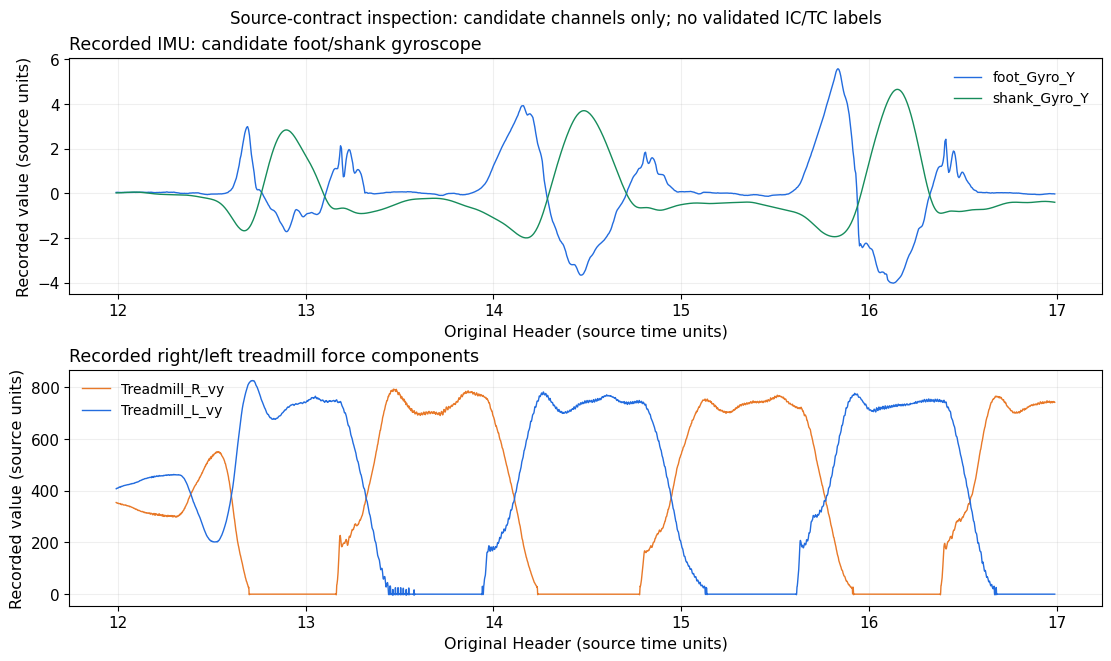

Original recorded diagnostic: AB06 treadmill_01_01
Native timestamp start difference: 0.0
Native timestamp end difference: 0.0
Descriptive source inspection complete. Contact-event extraction is still blocked pending physical channel and timebase verification.
Evidence saved to: /content/human-movement-intelligence/gait_analysis/output/02_source_contract_review.csv


In [4]:
# ==================== 02. Review Original Sensor Contract ====================

# ------------- 1. Load Recorded Source Pair and Channel Evidence -------------
pair_file = output_dir / "01_candidate_pairs.csv"
column_file = output_dir / "01_observed_columns.csv"
timebase_file = output_dir / "01_trial_timebase_audit.csv"
if not pair_file.is_file() or not column_file.is_file():
    raise FileNotFoundError(
        "Notebook 01's candidate pairs and observed columns are missing. "
        "Run Notebook 01 Sections 03–07 before inspecting references."
    )
pairs = pd.read_csv(pair_file)
pairs = pairs.loc[
    pairs.candidate_pair & pairs.condition.eq("treadmill")
].copy()
observed = pd.read_csv(column_file)
if pairs.empty:
    raise ValueError("No source-matched treadmill IMU/force trial pairs.")

# --------------------- 1A. Check Raw Source Availability ---------------------
pair_keys = ["subject_id", "session_id", "condition", "trial_id"]
raw_imu_ok = [(source_root / str(p)).is_file() for p in pairs.imu_path]
raw_force_ok = [(source_root / str(p)).is_file() for p in pairs.fp_path]
original_mat_ready = bool(all(raw_imu_ok) and all(raw_force_ok))
if not original_mat_ready:
    missing_pairs = pairs.loc[
        np.logical_not(np.asarray(raw_imu_ok) & np.asarray(raw_force_ok)),
        ["subject_id", "session_id", "trial_id"]
    ]
    raise FileNotFoundError(
        "Selected original Camargo IMU/Force MAT recordings are missing "
        "in this Colab runtime. Run Notebook 01 (Sections 00–07) to "
        "acquire all selected source recordings, then run Notebook 02 "
        "in the SAME runtime. Missing trial examples: "
        + missing_pairs.head(5).to_dict("records").__repr__()
    )
print("All selected original IMU/force recordings are available locally.")

# ----------------- 1B. Check Original Auxiliary Source Paths -----------------
auxiliary_manifest = output_dir / "01_auxiliary_source_inventory.csv"
auxiliary_types = ("gcRight", "gcLeft", "conditions")
aux_keys = pair_keys + ["sensor"]
expected_rows = []
for trial in pairs.itertuples(index=False):
    for sensor in auxiliary_types:
        relative = (
            Path(trial.fp_path).parent.parent / sensor /
            Path(trial.fp_path).name
        ).as_posix()
        expected_rows.append({
            "subject_id": str(trial.subject_id),
            "session_id": str(trial.session_id),
            "condition": str(trial.condition),
            "trial_id": str(trial.trial_id), "sensor": sensor,
            "relative_path": relative,
            "present_in_runtime": (source_root / relative).is_file(),
        })
auxiliary_crosscheck = pd.DataFrame(expected_rows)
if auxiliary_manifest.is_file():
    saved_aux = pd.read_csv(
        auxiliary_manifest,
        dtype={key: str for key in pair_keys},
    )
    required = set(aux_keys + ["relative_path", "source_status"])
    if required.difference(saved_aux.columns):
        raise ValueError(
            "The Notebook 01 supplementary-source inventory has "
            "incomplete source-identification columns."
        )
    if saved_aux.duplicated(aux_keys).any():
        raise ValueError("Duplicate auxiliary source-trial identifiers.")
    if set(map(tuple, saved_aux[aux_keys].astype(str).to_numpy())) != set(
        map(tuple, auxiliary_crosscheck[aux_keys].to_numpy())
    ):
        raise ValueError(
            "Notebook 01 supplementary trial identifiers differ from "
            "the paired IMU/force source cohort."
        )
    checked = auxiliary_crosscheck.merge(
        saved_aux[aux_keys + ["relative_path", "source_status"]],
        on=aux_keys, validate="one_to_one",
        suffixes=("", "_notebook01"),
    )
    if not checked.relative_path.eq(
        checked.relative_path_notebook01
    ).all():
        raise ValueError("An original auxiliary source path is inconsistent.")
    auxiliary_crosscheck["notebook01_status"] = (
        checked.source_status.to_numpy()
    )
else:
    auxiliary_crosscheck["notebook01_status"] = (
        "no_notebook01_auxiliary_inventory"
    )
    print("Notebook 01 auxiliary inventory absent; run its revised "
          "source-acquisition section for complete provenance.")
auxiliary_crosscheck["independent_reference_verified"] = False
auxiliary_crosscheck.to_csv(
    output_dir / "02_auxiliary_source_crosscheck.csv", index=False
)
print("Original supplementary source files available in this runtime:",
      auxiliary_crosscheck.groupby("sensor").present_in_runtime.sum()
      .astype(int).to_dict())
print("Supplementary availability does not verify phase, force units, "
      "physical side or event-level timing.")

imu_names = set(observed.loc[observed.modality == "imu", "column"])
fp_names = set(observed.loc[observed.modality == "fp", "column"])
if timebase_file.is_file():
    timebase_audit = pd.read_csv(timebase_file)
    if len(timebase_audit) != len(pairs):
        print("Trial-level timestamp audit is incomplete; rerun "
              "Notebook 01 Sections 05–07 to refresh the evidence.")
else:
    timebase_audit = pd.DataFrame()
    print("Trial-level timestamp audit missing. Rerun updated "
          "Notebook 01 Section 05 before reference extraction.")
print("Source-paired people:", pairs.subject_id.nunique())
print("Candidate source pairs:", len(pairs))
print("Gyroscope fields:", sorted(
    name for name in imu_names if "Gyro" in name
))
print("Treadmill force fields:", sorted(
    name for name in fp_names
    if "Treadmill_" in name and "_v" in name
))
if not timebase_audit.empty:
    display(timebase_audit)


# ------------------- 2. Save Scientific Contract Evidence --------------------
contract_review = pd.DataFrame([
    {"setting": "GYRO_COLUMN", "candidate": "foot_Gyro_Y",
     "observed": "foot_Gyro_Y" in imu_names,
     "unresolved": "Fixed observed model-input axis; do not claim anatomical orientation or Test-derived selection."},
    {"setting": "VERTICAL_FORCE_COLUMN",
     "candidate": "Treadmill_R_vy",
     "observed": "Treadmill_R_vy" in fp_names,
     "unresolved": "Verify physical vertical axis, source units and belt side."},
    {"setting": "FOOT_SIDE", "candidate": "right (author-reported)",
     "observed": pd.NA,
     "unresolved": "Right-sided wearable IMU in Camargo et al. (2021); verify R/L treadmill belt correspondence."},
    {"setting": "FORCE_UPWARD_SIGN", "candidate": "positive (candidate)",
     "observed": pd.NA,
     "unresolved": "Verify the real loading polarity and swing-phase baseline."},
    {"setting": "TIME_UNIT_IN_SECONDS",
     "candidate": "1.0 (seconds in source paper)",
     "observed": pd.NA,
     "unresolved": "Header time in seconds reported by Camargo et al. (2021); native 200/1000-Hz steps observed."},
    {"setting": "IMU_FORCE_TIMEBASE_CONFIRMED",
     "candidate": "not confirmed", "observed": pd.NA,
     "unresolved": "Confirm a common event-level clock for retained trials."},
    {"setting": "FORCE_SCALE_TO_NEWTONS", "candidate": "not confirmed",
     "observed": pd.NA,
     "unresolved": "Confirm conversion from original force units to newtons."},
])
display(contract_review)
contract_review.to_csv(
    output_dir / "02_source_contract_review.csv", index=False
)

# ------------- 3. Inspect Recorded Right-Left Treadmill Signals --------------
sample = pairs.iloc[0]
imu_path = source_root / sample.imu_path
fp_path = source_root / sample.fp_path
if imu_path.is_file() and fp_path.is_file():
    inspect_imu = read_sensor_table(imu_path)
    inspect_fp = read_sensor_table(fp_path)
    time_imu = validate_timebase(inspect_imu, "IMU")
    time_fp = validate_timebase(inspect_fp, "force")
    fig, axes = plt.subplots(
        2, 1, figsize=(11, 6.5), layout="constrained"
    )
    trial_window_imu = time_imu <= time_imu[0] + 5.0
    trial_window_fp = time_fp <= time_fp[0] + 5.0
    for name, colour in (
        ("foot_Gyro_Y", "#236CDE"),
        ("shank_Gyro_Y", "#168C5B"),
    ):
        if name in inspect_imu:
            axes[0].plot(
                time_imu[trial_window_imu],
                inspect_imu.loc[trial_window_imu, name],
                label=name, color=colour, linewidth=1,
            )
    for name, colour in (
        ("Treadmill_R_vy", "#E87929"),
        ("Treadmill_L_vy", "#236CDE"),
    ):
        if name in inspect_fp:
            axes[1].plot(
                time_fp[trial_window_fp],
                inspect_fp.loc[trial_window_fp, name],
                label=name, color=colour, linewidth=1,
            )
    for ax, title in zip(axes, (
        "Recorded IMU: candidate foot/shank gyroscope",
        "Recorded right/left treadmill force components",
    )):
        ax.set_title(title, loc="left")
        ax.set_xlabel("Original Header (source time units)")
        ax.set_ylabel("Recorded value (source units)")
        if ax.lines:
            ax.legend(frameon=False)
        ax.grid(alpha=0.2)
    fig.suptitle(
        "Source-contract inspection: candidate channels only; "
        "no validated IC/TC labels"
    )
    save_figure(fig, output_dir / "02_source_contract_diagnostic.png")
    plt.show()
    print("Original recorded diagnostic:", sample.subject_id,
          sample.trial_id)
    print("Native timestamp start difference:",
          float(time_imu[0] - time_fp[0]))
    print("Native timestamp end difference:",
          float(time_imu[-1] - time_fp[-1]))
else:
    raise FileNotFoundError(
        "The selected source recording disappeared during Notebook 02. "
        "Restart Notebook 01 acquisition in this Colab runtime."
    )

# ------------------ 4. Retain Unverified Physical Contract -------------------
# These are intentionally unset; source column names are not proof of units.
GYRO_COLUMN = None
VERTICAL_FORCE_COLUMN = None
FOOT_SIDE = None
FORCE_UPWARD_SIGN = None
TIME_UNIT_IN_SECONDS = None
FORCE_SCALE_TO_NEWTONS = None
IMU_FORCE_TIMEBASE_CONFIRMED = False
REFERENCE_THRESHOLD_N = 20.0
ANALYSED_CONDITIONS = {"treadmill"}
print("Descriptive source inspection complete. Contact-event extraction "
      "is still blocked pending physical channel and timebase verification.")
print("Evidence saved to:", output_dir / "02_source_contract_review.csv")


**02A. Cross-Trial Physical Source Evidence**

This source-only stage reads every selected original treadmill IMU/force pair and compares right/left treadmill force components (`vx`, `vy`, `vz`), native timestamps and foot gyroscope axes. If original MAT inputs are unavailable, Section 02 stops before creating outputs and directs the reader to Notebook 01. All numerical values remain in original source units.

No component is automatically declared vertical, no belt is assigned to a foot, and no IC/TC markers are generated in this inspection. The new `02_force_channel_screening.csv` records median original-unit component distributions across inspected trials, without approving physical axes, Newton units or foot-side mapping. The nominal 200/1,000-Hz sensor rates and `Header` timestamp convention are source descriptions, not independent proof of event-level synchronization.

After reviewing the original files, independently establish the gyro axis, physical force component, foot side, loading sign, force conversion to newtons, timestamp units and common clock. The proposed 20-N contact threshold is meaningful only for genuine Newton-valued force. Sections 03–05 remain deferred until that evidence exists.

**Recorded cross-trial evidence:** The latest saved diagnostics inspected all 27 selected IMU/force pairs and six labelled treadmill force components. The resulting source distributions and plots are measurements from the original files, but their channel names and magnitudes do not establish physical vertical orientation, contact side, scale or sign.


In [5]:
# ===================== 02A. Cross-Trial Source Evidence ======================

# ----------------------- 1. Inspect Every Source Pair ------------------------
trial_evidence, component_evidence = audit_candidate_pairs(
    pairs, source_root, read_sensor_table, validate_timebase
)
if (trial_evidence.empty or component_evidence.empty or
        not trial_evidence.inspection_status.eq("inspected").all()):
    raise ValueError(
        "The selected raw MAT source audit did not complete; review the "
        "reported trial failures before replacing saved source outputs."
    )
trial_evidence.to_csv(
    output_dir / "02_contract_evidence_by_trial.csv", index=False
)
component_evidence.to_csv(
    output_dir / "02_force_component_evidence.csv", index=False
)
print("Actual original source pairs inspected:", len(trial_evidence))
display(trial_evidence)
display(component_evidence.head(12))

# ---------------------- 2. Plot a Recorded Source Trial ----------------------
plot_source_contract_probe(
    pairs.iloc[0], source_root,
    read_sensor_table, validate_timebase,
    output_dir / "02_all_force_axes_source_probe.png",
)
print("Source-only multi-axis figure saved from original MAT.")

# ------------------- 3. Summarise Measured Source Channels -------------------
channel_screening = (
    component_evidence.groupby("channel", as_index=False)
    .agg(
        n_inspected_trials=("trial_id", "size"),
        median_p01_source=("p01_source", "median"),
        median_p99_source=("p99_source", "median"),
        median_signal_source=("median_source", "median"),
        median_near_zero_fraction=(
            "near_zero_fraction_relative", "median"
        ),
    )
    .sort_values("channel", kind="stable").reset_index(drop=True)
)
channel_screening["physical_axis_verified"] = False
channel_screening["units_verified_newtons"] = False
channel_screening["foot_side_verified"] = False
channel_screening.to_csv(
    output_dir / "02_force_channel_screening.csv", index=False
)
display(channel_screening)
print("Source amplitudes do not establish Newton scale or physical axes.")


Actual original source pairs inspected: 27


,subject_id,session_id,condition,trial_id,inspection_status,imu_start_header,imu_end_header,imu_median_header_step,imu_max_step_over_median,imu_samples_per_header_unit,...,fp_max_step_over_median,fp_samples_per_header_unit,fp_n_samples,start_difference_header,end_difference_header,overlap_header,time_overlap_not_clock_proof,observed_force_component_count,observed_foot_gyro_axes,inspection_note
0,AB06,10_09_18,treadmill,treadmill_01_01,inspected,11.990,155.045,0.005,1.0,200.0,...,1.0,1000.0,143056,0.000,0.0,143.055,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
1,AB06,10_09_18,treadmill,treadmill_04_01,inspected,12.475,156.035,0.005,1.0,200.0,...,1.0,1000.0,143564,0.003,0.0,143.560,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
2,AB06,10_09_18,treadmill,treadmill_08_01,inspected,10.680,154.900,0.005,1.0,200.0,...,1.0,1000.0,144223,0.002,0.0,144.220,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
3,AB07,10_14_18,treadmill,treadmill_01_01,inspected,10.360,153.415,0.005,1.0,200.0,...,1.0,1000.0,143057,0.001,0.0,143.055,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
4,AB07,10_14_18,treadmill,treadmill_04_2_01,inspected,10.025,153.585,0.005,1.0,200.0,...,1.0,1000.0,143565,0.004,0.0,143.560,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
5,AB07,10_14_18,treadmill,treadmill_08_01,inspected,8.795,153.015,0.005,1.0,200.0,...,1.0,1000.0,144223,0.002,0.0,144.220,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
6,AB08,10_21_2018,treadmill,treadmill_01_01,inspected,8.630,151.525,0.005,1.0,200.0,...,1.0,1000.0,142899,0.003,0.0,142.895,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
7,AB08,10_21_2018,treadmill,treadmill_04_01,inspected,12.085,155.470,0.005,1.0,200.0,...,1.0,1000.0,143389,0.003,0.0,143.385,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
8,AB08,10_21_2018,treadmill,treadmill_07_01,inspected,9.575,153.455,0.005,1.0,200.0,...,1.0,1000.0,143883,0.002,0.0,143.880,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",
9,AB09,10_21_2018,treadmill,treadmill_01_01,inspected,14.020,156.920,0.005,1.0,200.0,...,1.0,1000.0,142904,0.003,0.0,142.900,True,6,"foot_Gyro_X,foot_Gyro_Y,foot_Gyro_Z",


,subject_id,session_id,condition,trial_id,channel,minimum_source,p01_source,p05_source,median_source,p95_source,p99_source,maximum_source,range_p01_p99_source,near_zero_fraction_relative
0,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vx,-177.344162,-73.292446,-5.132414e+01,-8.967167e+00,9.884792,49.083442,205.315979,122.375887,0.368436
1,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vy,-28.178368,-0.132820,-3.858219e-08,4.472218e+02,796.272919,919.923779,1132.573608,920.056599,0.359503
2,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vz,-249.813629,-174.448101,-1.141733e+02,2.301347e-38,97.734385,160.319534,239.562149,334.767635,0.389085
3,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vx,-121.150627,-16.340124,-1.086319e+00,2.388388e+01,69.545609,92.556512,158.043320,108.896637,0.294878
4,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vy,-43.941357,-5.453911,-1.464031e-01,4.567940e+02,784.363159,894.283160,1119.963745,899.737072,0.334953
5,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vz,-268.893890,-175.411132,-1.077300e+02,3.367511e-33,90.260395,153.727378,249.851608,329.138510,0.372015
6,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vx,-303.573608,-90.942383,-4.806519e+01,-5.187988e+00,18.539429,94.327545,345.840454,185.269928,0.376989
7,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vy,-33.874512,0.000000,0.000000e+00,4.418945e+02,818.176270,973.109436,1153.259277,973.109436,0.364883
8,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vz,-266.494751,-184.020996,-1.219940e+02,0.000000e+00,105.438232,181.579590,315.704346,365.600586,0.387117
9,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_L_vx,-174.942017,-34.790039,0.000000e+00,2.166748e+01,65.765381,99.210358,230.560303,134.000397,0.350359


Source-only multi-axis figure saved from original MAT.


,channel,n_inspected_trials,median_p01_source,median_p99_source,median_signal_source,median_near_zero_fraction,physical_axis_verified,units_verified_newtons,foot_side_verified
0,Treadmill_L_vx,27,-28.762817,99.210358,18.539429,0.377403,False,False,False
1,Treadmill_L_vy,27,0.000000,930.328369,398.559570,0.369030,False,False,False
2,Treadmill_L_vz,27,-199.203491,190.429688,0.000000,0.395790,False,False,False
3,Treadmill_R_vx,27,-93.154907,32.043457,-15.411377,0.391339,False,False,False
4,Treadmill_R_vy,27,0.000000,921.806335,409.393311,0.377508,False,False,False
5,Treadmill_R_vz,27,-202.151489,198.931122,0.000000,0.410331,False,False,False


Source amplitudes do not establish Newton scale or physical axes.


**02A.1. Measured-Force Contact Candidate Diagnostics (Not Final References)**

This stage directly reads the prepared original force MAT recordings and analyses both source-labelled treadmill `vy` channels. It does not replace source signals with previously published candidate CSVs. If files are missing, the upfront source check directs the reader to Notebook 01. It compares crossings at 10, 20 and 30 **original recorded units**, not verified Newton values. The approved scientific reference threshold is still 20 N; it is **not** applied as a physical reference until units, force direction, belt/foot correspondence and event clock are established.

Outputs: `02_candidate_contact_trial_audit.csv`, `02_candidate_contact_intervals.csv`, and `02_candidate_force_probe.png`. These are real-source diagnostic outputs, not validated IC/TC reference events; do not rename them or use them in Notebook 03, model training or Test analysis.

**Recorded findings:** The candidate audit contains 162 trial/side/threshold rows across 27 trials, two labelled treadmill sides and three thresholds. At 20 original recorded units it produced 1,806 onset candidates across both sides; the source-labelled right channel contributes 1,145 candidates. These are source-unit events rather than independent IC/TC labels. More threshold crossings at a higher threshold do not, by themselves, imply more accurate gait-event recovery.


In [6]:
# =================== 02A.1. Source Contact Candidate Audit ===================

# ----------------------- 1. Audit Original Force Data ------------------------
candidate_audit, candidate_intervals = audit_recorded_force_candidates(
    pairs, source_root, read_sensor_table, validate_timebase,
    thresholds_recorded=(10.0, 20.0, 30.0),
)
if (candidate_audit.empty or candidate_intervals.empty or
        not candidate_audit.inspection_status.eq("inspected").all()):
    raise ValueError(
        "Original force candidate extraction was incomplete. Review "
        "source errors before replacing the existing trial evidence."
    )
candidate_audit.to_csv(
    output_dir / "02_candidate_contact_trial_audit.csv", index=False
)
candidate_intervals.to_csv(
    output_dir / "02_candidate_contact_intervals.csv", index=False
)
print("Trial/side/threshold audit rows:", len(candidate_audit))
print("Onset candidates at 20 original units:", len(candidate_intervals))
display(candidate_audit.head(12))

# --------------------- 2. Plot Measured Force Candidates ---------------------
sample_pair = pairs.iloc[0]
table = read_sensor_table(source_root / sample_pair.fp_path)
header = validate_timebase(table, "force")
selected = pd.Series(True, index=candidate_intervals.index)
for field in ("subject_id", "session_id", "condition", "trial_id"):
    selected &= candidate_intervals[field].astype(str).eq(
        str(sample_pair[field])
    )
plot_recorded_force_candidate_probe(
    table, header, candidate_intervals.loc[selected],
    output_dir / "02_candidate_force_probe.png",
)
print("Original force candidate plot saved. None are verified IC/TC.")


Trial/side/threshold audit rows: 162
Onset candidates at 20 original units: 1806


,subject_id,session_id,condition,trial_id,candidate_channel,threshold_recorded_units,inspection_status,n_contact_candidates,n_plausible_same_side_intervals,median_same_side_interval_header,median_candidate_duration_header,source_p99,source_p01,physical_reference_validated,inspection_note
0,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vy,10.0,inspected,30,7,1.4780,0.8020,919.923779,-0.132820,False,
1,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vy,20.0,inspected,62,43,1.2330,0.6285,919.923779,-0.132820,False,
2,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vy,30.0,inspected,77,62,1.0260,0.6250,919.923779,-0.132820,False,
3,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vy,10.0,inspected,9,3,1.5530,1.0670,894.283160,-5.453911,False,
4,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vy,20.0,inspected,20,10,1.2625,0.5545,894.283160,-5.453911,False,
5,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vy,30.0,inspected,29,24,1.2260,0.5440,894.283160,-5.453911,False,
6,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vy,10.0,inspected,16,8,1.2925,0.7440,973.109436,0.000000,False,
7,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vy,20.0,inspected,34,18,1.2925,0.5955,973.109436,0.000000,False,
8,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vy,30.0,inspected,72,62,1.3395,0.5940,973.109436,0.000000,False,
9,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_L_vy,10.0,inspected,14,9,1.1260,0.7130,930.328369,0.000000,False,


Original force candidate plot saved. None are verified IC/TC.


**02A.2. Original-Source Contact Quality and Gait-Phase Audit**

This section tests the **actual** 27-trial, both-side candidate tables. It reconciles the 20-recorded-unit contact intervals with the trial audit, compares 10/20/30 *recorded-unit* thresholds, and flags low-yield or threshold-sensitive trials for review. These are descriptive warning thresholds, **not** model selection, exclusion decisions or physical Newton validation.

The [original Camargo Part 1 v1 README](https://data.mendeley.com/datasets/fcgm3chfff/1) lists a same-trial `gcRight` gait-phase stream. All 27 matching original `gcRight` files were present during the recorded Notebook 01 execution. This section inspects their actual fields and possible `HeelStrike` phase resets if those files remain in the active Colab runtime. The `gcLeft` and `conditions` streams are audited for availability in Section 02 rather than used as contact-reference labels. Phase resets are **not automatically independent force-reference IC labels**. No time offset is estimated using IMU predictions.

Outputs: `02_candidate_quality_review.csv`, `02_candidate_threshold_sensitivity.png`, `02_original_gcright_source_audit.csv` and `02_original_gcright_phase_resets.csv`. When a valid original phase stream is available, `02_original_phase_force_comparison.csv` reports one-to-one temporal proximity within the study's fixed 150-ms tolerance, **without optimising an offset**. These are not `02_reference_events.csv`.

**Recorded findings:** [`02_candidate_quality_review.csv`](../../output/02_candidate_quality_review.csv) contains 54 trial/side rows, including 39 threshold-sensitive cases and 21 low-yield cases. All 27 original `gcRight` streams were inspected and yielded 3,538 possible `HeelStrike` phase-wrap candidates. The [same-trial phase/force comparison](../../output/02_original_phase_force_comparison.csv) reports 1,134 one-to-one near matches among 1,145 right-channel source-unit force-onset candidates, within the fixed 150-ms tolerance and without fitted time shifts. However, 2,404 phase wraps remain unmatched. This is **proximity evidence, not event sensitivity, independent ground truth, or proof of IMU/force clock synchronisation**. The phase provenance and physical force contract remain unresolved.

**Targeted follow-up diagnostics (not yet executed on original MAT files):** This section additionally produces `02_original_phase_both_sides_comparison.csv`, using the same fixed 150-ms matching tolerance for both source-labelled treadmill sides. It also produces `02_contact_filter_loss_review.csv`, counting how many original-unit loaded segments are discarded by the current minimum-contact and minimum-swing checks, at the existing 20-recorded-unit threshold. These diagnostics distinguish wrong-side correspondence from event loss caused by filtering; they do **not** change the extraction method, establish Newton units or construct independent IC/TC labels. The two new outputs must be generated by re-executing Section 02A.2 with original MAT files present.


Source candidate trial/side records: 54
Threshold-sensitive cases: 39
Low candidate-yield cases: 21


,subject_id,session_id,condition,trial_id,candidate_channel,10.0,20.0,30.0,n_saved_candidates,median_contact_duration_header,overlap_header,candidates_per_minute,count_ratio_30_over_10,threshold_sensitive_review,low_yield_review,physical_reference_validated,role
0,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_L_vy,9,20,29,20,0.5545,143.055,8.388382,3.000000,True,True,False,descriptive QC only; not reference exclusion
1,AB06,10_09_18,treadmill,treadmill_01_01,Treadmill_R_vy,30,62,77,62,0.6285,143.055,26.003984,2.516129,True,False,False,descriptive QC only; not reference exclusion
2,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_L_vy,14,17,59,17,0.7130,143.560,7.105043,4.000000,True,True,False,descriptive QC only; not reference exclusion
3,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vy,16,34,72,34,0.5955,143.560,14.210086,4.294118,True,False,False,descriptive QC only; not reference exclusion
4,AB06,10_09_18,treadmill,treadmill_08_01,Treadmill_L_vy,0,0,22,0,NaN,144.220,0.000000,23.000000,True,True,False,descriptive QC only; not reference exclusion
5,AB06,10_09_18,treadmill,treadmill_08_01,Treadmill_R_vy,3,4,32,4,0.6985,144.220,1.664124,8.250000,True,True,False,descriptive QC only; not reference exclusion
6,AB07,10_14_18,treadmill,treadmill_01_01,Treadmill_L_vy,20,35,41,35,0.9700,143.055,14.679669,2.000000,True,False,False,descriptive QC only; not reference exclusion
8,AB07,10_14_18,treadmill,treadmill_04_2_01,Treadmill_L_vy,32,51,69,51,0.6360,143.560,21.315130,2.121212,True,False,False,descriptive QC only; not reference exclusion
10,AB07,10_14_18,treadmill,treadmill_08_01,Treadmill_L_vy,9,47,72,47,0.5110,144.220,19.553460,7.300000,True,False,False,descriptive QC only; not reference exclusion
11,AB07,10_14_18,treadmill,treadmill_08_01,Treadmill_R_vy,48,53,74,53,0.6770,144.220,22.049646,1.530612,True,False,False,descriptive QC only; not reference exclusion


These are review flags only; no participants or trials are excluded.


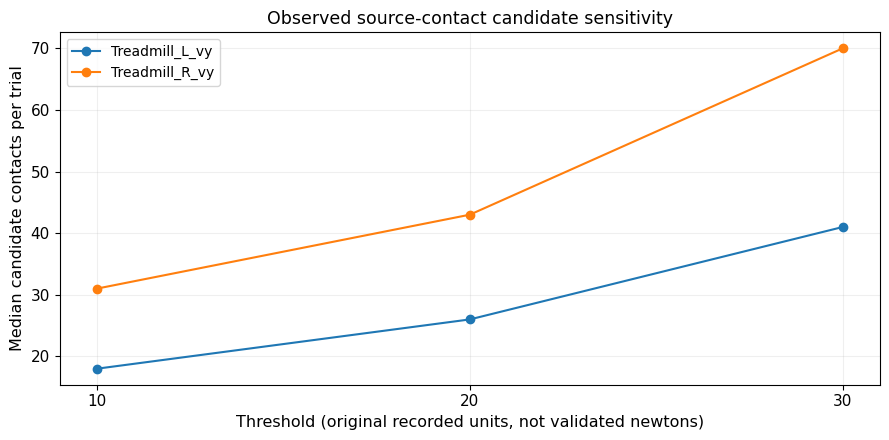

Original gait-phase source availability: {'original_phase_inspected': 27}
Possible original phase wraps: 3538
Phase wraps are corroborating source candidates, not proven independent force-contact references.


,subject_id,session_id,condition,trial_id,gc_right_path,source_status,observed_columns,n_phase_wrap_candidates,independent_reference_verified
0,AB06,10_09_18,treadmill,treadmill_01_01,AB06/10_09_18/treadmill/gcRight/treadmill_01_0...,original_phase_inspected,"Header,HeelStrike,ToeOff",124,False
1,AB06,10_09_18,treadmill,treadmill_04_01,AB06/10_09_18/treadmill/gcRight/treadmill_04_0...,original_phase_inspected,"Header,HeelStrike,ToeOff",134,False
2,AB06,10_09_18,treadmill,treadmill_08_01,AB06/10_09_18/treadmill/gcRight/treadmill_08_0...,original_phase_inspected,"Header,HeelStrike,ToeOff",141,False
3,AB07,10_14_18,treadmill,treadmill_01_01,AB07/10_14_18/treadmill/gcRight/treadmill_01_0...,original_phase_inspected,"Header,HeelStrike,ToeOff",118,False
4,AB07,10_14_18,treadmill,treadmill_04_2_01,AB07/10_14_18/treadmill/gcRight/treadmill_04_2...,original_phase_inspected,"Header,HeelStrike,ToeOff",128,False
5,AB07,10_14_18,treadmill,treadmill_08_01,AB07/10_14_18/treadmill/gcRight/treadmill_08_0...,original_phase_inspected,"Header,HeelStrike,ToeOff",136,False
6,AB08,10_21_2018,treadmill,treadmill_01_01,AB08/10_21_2018/treadmill/gcRight/treadmill_01...,original_phase_inspected,"Header,HeelStrike,ToeOff",120,False
7,AB08,10_21_2018,treadmill,treadmill_04_01,AB08/10_21_2018/treadmill/gcRight/treadmill_04...,original_phase_inspected,"Header,HeelStrike,ToeOff",125,False
8,AB08,10_21_2018,treadmill,treadmill_07_01,AB08/10_21_2018/treadmill/gcRight/treadmill_07...,original_phase_inspected,"Header,HeelStrike,ToeOff",135,False
9,AB09,10_21_2018,treadmill,treadmill_01_01,AB09/10_21_2018/treadmill/gcRight/treadmill_01...,original_phase_inspected,"Header,HeelStrike,ToeOff",117,False


Original-source clock coincidence by trial (no offset fitting):


,subject_id,session_id,condition,trial_id,n_phase_wrap_candidates,n_recorded_force_candidates,n_time_near_matches,median_absolute_difference_ms,unmatched_phase_wraps,unmatched_force_candidates,independent_reference_verified
0,AB06,10_09_18,treadmill,treadmill_01_01,124,62,61,8.0,63,1,False
1,AB06,10_09_18,treadmill,treadmill_04_01,134,34,34,7.5,100,0,False
2,AB06,10_09_18,treadmill,treadmill_08_01,141,4,4,7.5,137,0,False
3,AB07,10_14_18,treadmill,treadmill_01_01,118,73,72,7.0,46,1,False
4,AB07,10_14_18,treadmill,treadmill_04_2_01,128,62,62,7.0,66,0,False
5,AB07,10_14_18,treadmill,treadmill_08_01,136,53,53,6.0,83,0,False
6,AB08,10_21_2018,treadmill,treadmill_01_01,120,33,32,14.5,88,1,False
7,AB08,10_21_2018,treadmill,treadmill_04_01,125,14,14,11.0,111,0,False
8,AB08,10_21_2018,treadmill,treadmill_07_01,135,15,15,7.0,120,0,False
9,AB09,10_21_2018,treadmill,treadmill_01_01,117,46,45,5.0,72,1,False


These matches do not independently certify Newton force, side correspondence or genuine IC/TC ground truth.
Original right gait-phase proximity to each labelled force side:


,candidate_channel,n_phase,n_force,n_near_matches
0,Treadmill_L_vy,3538,661,0
1,Treadmill_R_vy,3538,1145,1134


This supports a source-side audit, not approval of reference labels.
Original-unit candidate filtering at 20 recorded units:


,candidate_channel,complete_segments,short_contact,short_swing,retained
0,Treadmill_L_vy,35349,31830,2858,661
1,Treadmill_R_vy,15805,12274,2386,1145


Review which filter removes candidate events before any independent-reference decision; no threshold or labels were changed.


In [7]:
# =================== 02A.2. Source Contact Quality Review ====================

# ------------------- 1. Reconcile Existing Source Contacts -------------------
quality_review = audit_contact_candidate_quality(
    candidate_audit, candidate_intervals, trial_evidence
)
quality_review.to_csv(
    output_dir / "02_candidate_quality_review.csv", index=False
)
print("Source candidate trial/side records:", len(quality_review))
print("Threshold-sensitive cases:",
      int(quality_review.threshold_sensitive_review.sum()))
print("Low candidate-yield cases:",
      int(quality_review.low_yield_review.sum()))
display(quality_review.loc[
    quality_review.threshold_sensitive_review |
    quality_review.low_yield_review
].head(18))
print("These are review flags only; no participants or trials are excluded.")

# ------------------ 2. Plot Original Threshold Sensitivity -------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
for channel in sorted(quality_review.candidate_channel.unique()):
    subset = quality_review.loc[quality_review.candidate_channel.eq(channel)]
    levels = np.array([10., 20., 30.])
    ax.plot(levels, [float(subset[k].median()) for k in levels],
            marker="o", label=channel)
ax.set(
    title="Observed source-contact candidate sensitivity",
    xlabel="Threshold (original recorded units, not validated newtons)",
    ylabel="Median candidate contacts per trial",
)
ax.set_xticks([10., 20., 30.])
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
save_figure(fig, output_dir / "02_candidate_threshold_sensitivity.png")
plt.show()

# -------------------- 3. Inspect Prepared Gait-Phase Data --------------------
# Notebook 01 owns source acquisition and selected auxiliary extraction.
# Missing original gcRight streams are audited, not silently downloaded here.
original_gc_audit, original_gc_resets = audit_original_gc_right(
    pairs, source_root, read_sensor_table, validate_timebase
)
original_gc_audit.to_csv(
    output_dir / "02_original_gcright_source_audit.csv", index=False
)
original_gc_resets.to_csv(
    output_dir / "02_original_gcright_phase_resets.csv", index=False
)
print("Original gait-phase source availability:",
      original_gc_audit.source_status.value_counts().to_dict())
print("Possible original phase wraps:", len(original_gc_resets))
print("Phase wraps are corroborating source candidates, not proven "
      "independent force-contact references.")
display(original_gc_audit.head(12))

# ---------- 4. Descriptive Phase/Force Coincidence, No Time Fitting ----------
phase_force_comparison = compare_original_phase_with_force_candidates(
    original_gc_resets, candidate_intervals, tolerance_s=0.150
)
phase_force_comparison.to_csv(
    output_dir / "02_original_phase_force_comparison.csv", index=False
)
if phase_force_comparison.empty:
    print("Phase/force comparison unavailable: matching original "
          "gcRight phase markers were not available.")
else:
    print("Original-source clock coincidence by trial (no offset fitting):")
    display(phase_force_comparison)
print("These matches do not independently certify Newton force, "
      "side correspondence or genuine IC/TC ground truth.")

# ------------- 5. Compare Both Belts Without Picking a Reference -------------
side_comparison = compare_phase_by_recorded_force_side(
    original_gc_resets, candidate_intervals, tolerance_s=0.150
)
side_comparison.to_csv(
    output_dir / "02_original_phase_both_sides_comparison.csv", index=False
)
print("Original right gait-phase proximity to each labelled force side:")
display(side_comparison.groupby("candidate_channel", as_index=False).agg(
    n_phase=("n_phase_wrap_candidates", "sum"),
    n_force=("n_recorded_force_candidates", "sum"),
    n_near_matches=("n_time_near_matches", "sum"),
))
print("This supports a source-side audit, not approval of reference labels.")

# --------------------- 6. Audit Candidate Filter Loss ------------------------
filter_loss = audit_source_contact_filter_loss(
    pairs, source_root, read_sensor_table, validate_timebase,
    threshold_recorded=20.0, min_contact_s=0.08, min_swing_s=0.06,
)
keys = ["subject_id", "session_id", "condition", "trial_id",
        "candidate_channel"]
expected = quality_review[keys + [20.0]].rename(
    columns={20.0: "n_expected_candidates"}
)
verified = filter_loss.merge(
    expected, on=keys, how="outer", validate="one_to_one",
    indicator=True,
)
if (not verified._merge.eq("both").all() or
        not verified.n_retained_candidates.eq(
            verified.n_expected_candidates
        ).all()):
    raise ValueError("Contact filter audit disagrees with saved candidate counts.")
filter_loss.to_csv(
    output_dir / "02_contact_filter_loss_review.csv", index=False
)
print("Original-unit candidate filtering at 20 recorded units:")
display(filter_loss.groupby("candidate_channel", as_index=False).agg(
    complete_segments=("n_complete_loaded_segments", "sum"),
    short_contact=("n_rejected_short_contact", "sum"),
    short_swing=("n_rejected_short_swing", "sum"),
    retained=("n_retained_candidates", "sum"),
))
print("Review which filter removes candidate events before any "
      "independent-reference decision; no threshold or labels were changed.")


**02A.3. Original-Force Gap-Stability Audit (Execution Pending)**

The executed Section 02A.2 found extensive fragmentation of the source-labelled treadmill `vy` channels at the exploratory threshold of 20 **recorded source units**. For 27 trials, the right-labelled channel contained 15,805 complete above-threshold segments, of which 12,274 failed the minimum-contact requirement and 2,386 failed the minimum-swing requirement. Only 1,145 were retained. This establishes why the present source-unit candidate extractor returns relatively few events, but does not establish which rejected segments are actual steps.

This follow-up evaluates the effect of bridging *only internal below-threshold gaps* of 0, 10, 20, 40 or 60 ms, with the existing 20-source-unit threshold, 80-ms minimum contact and 60-ms minimum swing unchanged. A gap is bridged only when it lies between two measured above-threshold portions. These values are a descriptive sensitivity grid, **not** an optimised reference-processing configuration. Both treadmill sides and every selected trial are reported. The 0-ms case is checked against the already recorded original candidate audit, rather than silently replacing it.

This section reads the original force MAT files, writes `02_source_gap_stability_review.csv` and a real-signal comparison `02_source_gap_stability_probe.png` from the previously flagged `AB06/treadmill_08_01` case. No `gcRight` labels or IMU predictions are used to select a gap setting. The figures and counts are exploratory and cannot be promoted to independent IC/TC references without documented force-axis orientation, units, polarity, foot correspondence and event-level timebase validation.

**Execution status:** This new analysis has not yet been run on the original MAT data. The existing Notebook 02 source outputs remain valid records of the earlier, unbridged extraction.


In [8]:
# ====================== 02A.3. Source Gap-Stability Audit ====================

# -- 1. Inspect Gap-Stability Grid and Verify Unbridged Baseline --------------
gap_stability = audit_source_gap_stability(
    pairs, source_root, read_sensor_table, validate_timebase,
    gap_durations_s=(0.0, 0.01, 0.02, 0.04, 0.06),
    threshold_recorded=20.0,
)
keys = ["subject_id", "session_id", "condition", "trial_id",
        "candidate_channel"]
baseline = gap_stability.loc[
    gap_stability.max_internal_gap_s.eq(0.0),
    keys + ["n_candidate_contacts"],
]
expected = candidate_audit.loc[
    candidate_audit.threshold_recorded_units.eq(20.0),
    keys + ["n_contact_candidates"],
]
checked = baseline.merge(expected, on=keys, how="outer",
                         indicator=True, validate="one_to_one")
if (not checked._merge.eq("both").all()
        or not checked.n_candidate_contacts.eq(
            checked.n_contact_candidates
        ).all()):
    raise ValueError(
        "Gap audit's unbridged case disagrees with the original "
        "force-source candidate audit. Do not replace saved outputs."
    )

# -- 2. Save Full Trial/Side Sensitivity --------------------------------------
gap_stability.to_csv(
    output_dir / "02_source_gap_stability_review.csv", index=False
)
print("Source-only gap sensitivity; no validated contact labels:")
display(gap_stability.groupby(
    ["candidate_channel", "max_internal_gap_s"], as_index=False
).agg(
    candidate_contacts=("n_candidate_contacts", "sum"),
    plausible_intervals=("n_plausible_same_side_intervals", "sum"),
    internal_gaps_bridged=("n_internal_gaps_bridged", "sum"),
))
print("No setting was selected or used to modify the formal reference.")

# -- 3. Inspect a Flagged Original Trial --------------------------------------
probe = pairs.loc[
    pairs.subject_id.eq("AB06") &
    pairs.trial_id.eq("treadmill_08_01")
]
if len(probe) != 1:
    raise ValueError("The published QC example requires one original trial.")
selected = probe.iloc[0]
original_force = read_sensor_table(source_root / selected.fp_path)
original_time = validate_timebase(original_force, "force")
plot_source_gap_stability_probe(
    original_force, original_time,
    output_dir / "02_source_gap_stability_probe.png",
    channel="Treadmill_R_vy", threshold_recorded=20.0,
    bridged_gap_s=0.04,
)
print("Actual force-signal diagnostic saved; not verified IC/TC.")


Source-only gap sensitivity; no validated contact labels:


,candidate_channel,max_internal_gap_s,candidate_contacts,plausible_intervals,internal_gaps_bridged
0,Treadmill_L_vy,0.00,661,425,0
1,Treadmill_L_vy,0.01,2058,1885,26524
2,Treadmill_L_vy,0.02,2384,2220,29183
3,Treadmill_L_vy,0.04,2845,2721,30531
4,Treadmill_L_vy,0.06,3373,3257,31326
5,Treadmill_R_vy,0.00,1145,840,0
6,Treadmill_R_vy,0.01,2581,2460,8301
7,Treadmill_R_vy,0.02,2894,2788,10742
8,Treadmill_R_vy,0.04,3195,3133,11574
9,Treadmill_R_vy,0.06,3458,3391,11955


No setting was selected or used to modify the formal reference.
Actual force-signal diagnostic saved; not verified IC/TC.


**02A.4. Original-Force / Gait-Phase Timing Cross-Check (Not Yet Executed)**

The earlier 02A.3 audit found that internal-gap closing increases source-force candidate counts. Count similarity alone is not sufficient: this stage checks the **original timing of individual onset candidates** against the available same-trial `gcRight.HeelStrike` phase wraps.

The comparison runs on all 27 selected original force trials, both treadmill sides, and the existing 0/10/20/40/60-ms gap settings at 20 **recorded source units**. It uses the fixed 150-ms, one-to-one, original-clock rule without fitting offsets. It also describes how many near pairs fall within 25 and 50 ms, unmatched events, the 95th-percentile absolute difference and the signed phase-minus-force difference. A strict baseline check confirms that zero-gap counts reproduce Section 02A.3 and previously published right-side phase/force correspondence.

Outputs: `02_source_gap_phase_timing_review.csv`, `02_source_gap_phase_timing_summary.csv` and an original-force and phase-annotation plot `02_source_gap_phase_timing_probe.png` for `AB06/treadmill_08_01`. The figure is displayed directly in the notebook as well as saved.

**Research boundary:** Gait-phase wraps are processed source annotations; their independence from force processing is unknown. They are corroboration only, not an independently verified IC/TC reference. Do not select the gap method, correct clocks, set eligibility, build reference labels or assess an IMU detector using this table. Physical axis, sign, Newton scale and synchronisation still require appropriate source-supported validation.


Fixed-clock source proximity, not independent IC accuracy:


,candidate_channel,max_internal_gap_s,n_trials,phase_wraps,force_candidates,near_matches_150ms,matched_within_25ms,matched_within_50ms,unmatched_phase,unmatched_force,median_of_trial_median_abs_ms,median_of_trial_median_signed_ms,near_matches_per_phase_wrap
0,Treadmill_L_vy,0.00,27,3538,661,0,0,0,3538,661,NaN,NaN,0.000000
1,Treadmill_L_vy,0.01,27,3538,2058,0,0,0,3538,2058,NaN,NaN,0.000000
2,Treadmill_L_vy,0.02,27,3538,2384,0,0,0,3538,2384,NaN,NaN,0.000000
3,Treadmill_L_vy,0.04,27,3538,2845,2,0,0,3536,2843,97.5,-42.5,0.000565
4,Treadmill_L_vy,0.06,27,3538,3373,4,0,0,3534,3369,140.0,-140.0,0.001131
5,Treadmill_R_vy,0.00,27,3538,1145,1134,1128,1132,2404,11,7.5,7.5,0.320520
6,Treadmill_R_vy,0.01,27,3538,2581,2561,2542,2558,977,20,8.0,8.0,0.723855
7,Treadmill_R_vy,0.02,27,3538,2894,2868,2825,2854,670,26,8.0,8.0,0.810627
8,Treadmill_R_vy,0.04,27,3538,3195,3155,3072,3119,383,40,7.5,7.5,0.891747
9,Treadmill_R_vy,0.06,27,3538,3458,3387,3248,3300,151,71,7.0,7.0,0.957321


Right-labelled source trials needing closer review at 60 ms:


,subject_id,session_id,condition,trial_id,candidate_channel,max_internal_gap_s,threshold_recorded_units,matching_tolerance_s,n_phase_wrap_candidates,n_recorded_force_candidates,...,n_matches_within_25ms,n_matches_within_50ms,n_unmatched_phase_wraps,n_unmatched_force_candidates,median_abs_time_difference_ms,p95_abs_time_difference_ms,median_signed_phase_minus_force_ms,phase_near_match_fraction,independent_reference_verified,analysis_role
144,AB10,10_28_2018,treadmill,treadmill_07_01,Treadmill_R_vy,0.06,20.0,0.15,142,80,...,49,53,69,7,14.0,139.80,14.0,0.514085,False,descriptive source-clock QC only
24,AB06,10_09_18,treadmill,treadmill_08_01,Treadmill_R_vy,0.06,20.0,0.15,141,108,...,99,101,34,1,7.0,50.90,7.0,0.758865,False,descriptive source-clock QC only
134,AB10,10_28_2018,treadmill,treadmill_04_01,Treadmill_R_vy,0.06,20.0,0.15,132,135,...,106,110,8,11,11.0,79.50,11.0,0.939394,False,descriptive source-clock QC only
124,AB10,10_28_2018,treadmill,treadmill_01_01,Treadmill_R_vy,0.06,20.0,0.15,122,129,...,96,103,5,12,13.0,82.60,13.0,0.959016,False,descriptive source-clock QC only
84,AB08,10_21_2018,treadmill,treadmill_07_01,Treadmill_R_vy,0.06,20.0,0.15,135,146,...,106,117,5,16,9.0,75.15,9.0,0.962963,False,descriptive source-clock QC only
204,AB12,11_04_2018,treadmill,treadmill_07_01,Treadmill_R_vy,0.06,20.0,0.15,137,136,...,127,130,4,3,7.0,14.00,7.0,0.970803,False,descriptive source-clock QC only
74,AB08,10_21_2018,treadmill,treadmill_04_01,Treadmill_R_vy,0.06,20.0,0.15,125,125,...,114,118,3,3,9.0,28.95,9.0,0.976000,False,descriptive source-clock QC only
54,AB07,10_14_18,treadmill,treadmill_08_01,Treadmill_R_vy,0.06,20.0,0.15,136,133,...,133,133,3,0,6.0,9.00,6.0,0.977941,False,descriptive source-clock QC only
64,AB08,10_21_2018,treadmill,treadmill_01_01,Treadmill_R_vy,0.06,20.0,0.15,120,121,...,108,113,2,3,10.0,32.00,10.0,0.983333,False,descriptive source-clock QC only
14,AB06,10_09_18,treadmill,treadmill_04_01,Treadmill_R_vy,0.06,20.0,0.15,134,133,...,132,132,2,1,8.0,14.00,8.0,0.985075,False,descriptive source-clock QC only


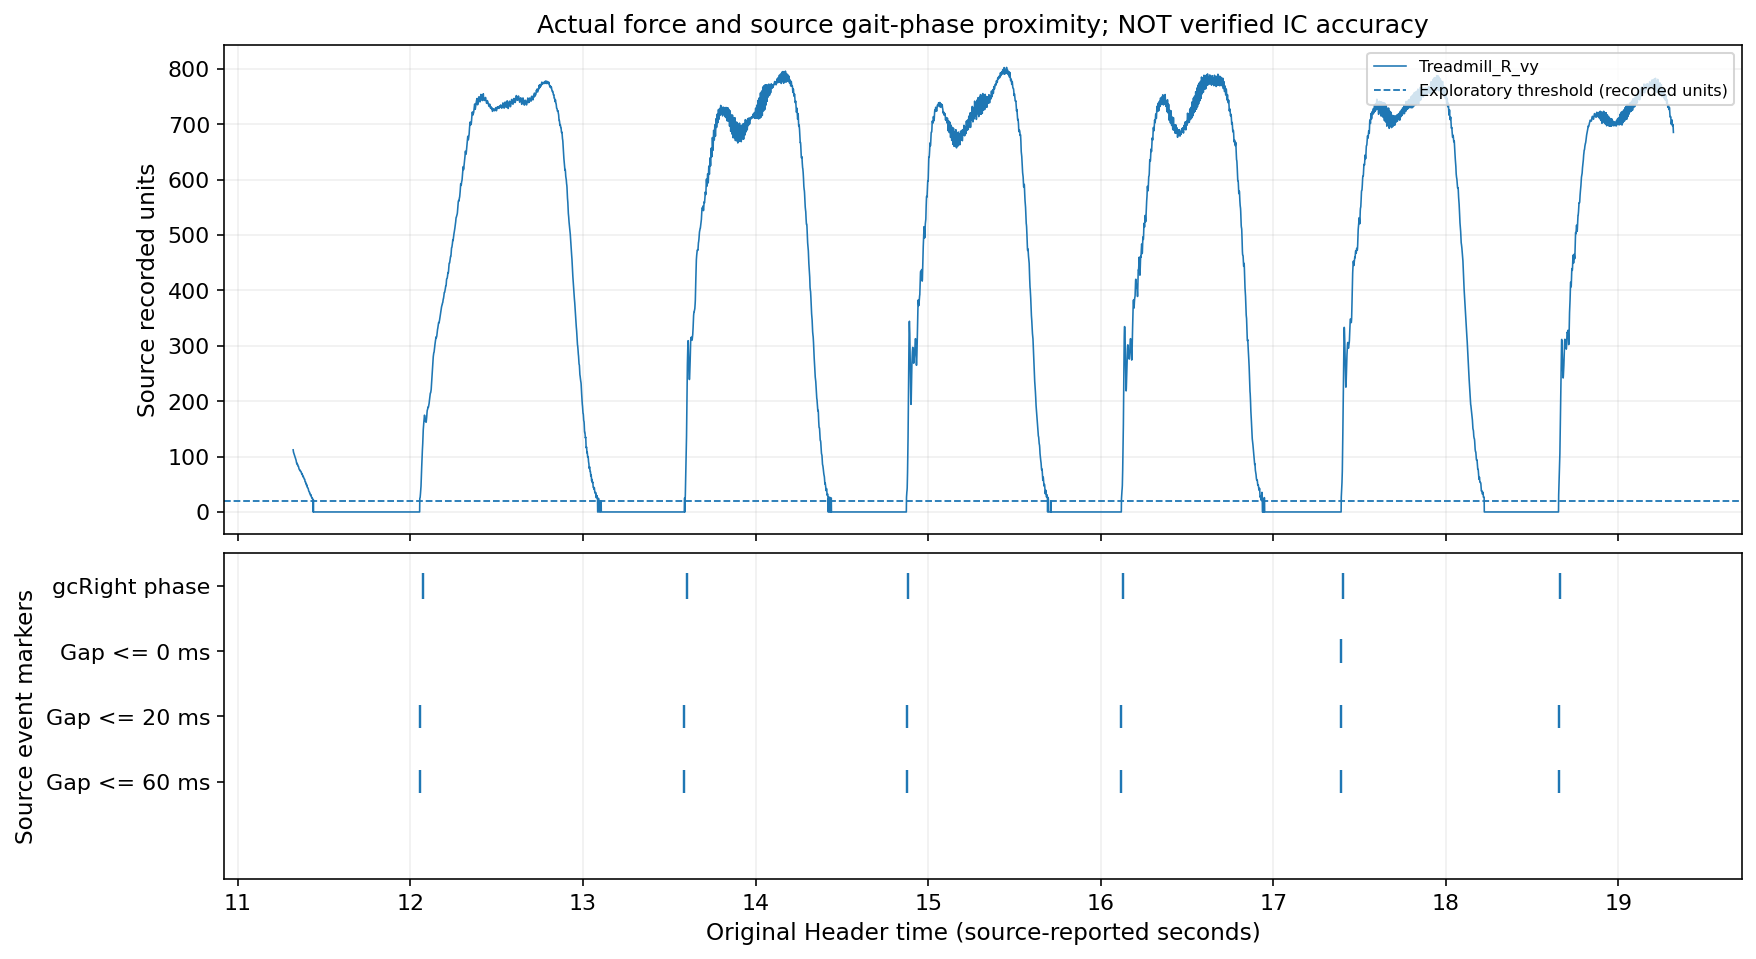

No gap method or force-reference contract was approved.


In [9]:
# ======== 02A.4. Original Source Gap/Phase Timing Cross-Check ================

# -------- 1. Compare Original Data Without Fitting Clock Shifts --------------
gap_phase = audit_source_gap_phase_timing(
    pairs, source_root, read_sensor_table, validate_timebase,
    original_gc_resets,
    gap_durations_s=(0.0, 0.01, 0.02, 0.04, 0.06),
    threshold_recorded=20.0, tolerance_s=0.150,
)

# -------- 2. Reconcile With Previously Executed Source Audits ----------------
keys = ["subject_id", "session_id", "condition", "trial_id",
        "candidate_channel", "max_internal_gap_s"]
previous = gap_stability[keys + ["n_candidate_contacts"]]
current = gap_phase[keys + ["n_recorded_force_candidates"]]
checked = previous.merge(current, on=keys, how="outer",
                         indicator=True, validate="one_to_one")
if (len(checked) != len(previous)
        or not checked._merge.eq("both").all()
        or not checked.n_candidate_contacts.eq(
            checked.n_recorded_force_candidates
        ).all()):
    raise ValueError("New gap/phase audit does not reproduce 02A.3 counts.")

zero_right = gap_phase.loc[
    gap_phase.candidate_channel.eq("Treadmill_R_vy") &
    gap_phase.max_internal_gap_s.eq(0.0)
]
prior = phase_force_comparison[[
    "subject_id", "session_id", "condition", "trial_id",
    "n_time_near_matches",
]]
baseline = zero_right.merge(
    prior, on=keys[:4], how="outer", validate="one_to_one",
    indicator=True, suffixes=("_new", "_prior")
)
if (len(baseline) != len(prior) or
        not baseline._merge.eq("both").all()
        or not baseline.n_time_near_matches_new.eq(
            baseline.n_time_near_matches_prior
        ).all()):
    raise ValueError("Zero-gap phase timing does not reproduce original QC.")

# -------- 3. Save Source Clock Quality Tables --------------------------------
gap_phase.to_csv(
    output_dir / "02_source_gap_phase_timing_review.csv", index=False
)
summary = gap_phase.groupby(
    ["candidate_channel", "max_internal_gap_s"], as_index=False
).agg(
    n_trials=("trial_id", "size"),
    phase_wraps=("n_phase_wrap_candidates", "sum"),
    force_candidates=("n_recorded_force_candidates", "sum"),
    near_matches_150ms=("n_time_near_matches", "sum"),
    matched_within_25ms=("n_matches_within_25ms", "sum"),
    matched_within_50ms=("n_matches_within_50ms", "sum"),
    unmatched_phase=("n_unmatched_phase_wraps", "sum"),
    unmatched_force=("n_unmatched_force_candidates", "sum"),
    median_of_trial_median_abs_ms=(
        "median_abs_time_difference_ms", "median"
    ),
    median_of_trial_median_signed_ms=(
        "median_signed_phase_minus_force_ms", "median"
    ),
)
summary["near_matches_per_phase_wrap"] = (
    summary.near_matches_150ms / summary.phase_wraps
)
summary.to_csv(
    output_dir / "02_source_gap_phase_timing_summary.csv", index=False
)
print("Fixed-clock source proximity, not independent IC accuracy:")
display(summary)
print("Right-labelled source trials needing closer review at 60 ms:")
display(gap_phase.loc[
    gap_phase.candidate_channel.eq("Treadmill_R_vy") &
    gap_phase.max_internal_gap_s.eq(0.06)
].sort_values("phase_near_match_fraction").head(10))

# -------- 4. Visualise Original Signal and Annotated Phase -------------------
probe = pairs.loc[
    pairs.subject_id.eq("AB06") &
    pairs.trial_id.eq("treadmill_08_01")
]
if len(probe) != 1:
    raise ValueError("Expected one original AB06 treadmill_08_01 trial.")
row = probe.iloc[0]
force_table = read_sensor_table(source_root / row.fp_path)
force_time = validate_timebase(force_table, "force")
phase = original_gc_resets.loc[
    original_gc_resets.subject_id.eq(str(row.subject_id)) &
    original_gc_resets.session_id.eq(str(row.session_id)) &
    original_gc_resets.condition.eq(str(row.condition)) &
    original_gc_resets.trial_id.eq(str(row.trial_id)),
    "phase_wrap_header"
]
if phase.empty:
    raise ValueError("Same-trial original phase annotation missing.")
fig_path = plot_original_gap_phase_probe(
    force_table, force_time, phase.to_numpy(float),
    output_dir / "02_source_gap_phase_timing_probe.png",
    channel="Treadmill_R_vy", threshold_recorded=20.0,
    gap_durations_s=(0.0, 0.02, 0.06), window_s=8.0,
)
display(Image(filename=str(fig_path)))
print("No gap method or force-reference contract was approved.")


**02A.5. Exploratory source-phase benchmark: independent of the force-reference claim**

This section enables an explicitly **secondary, exploratory** evaluation of foot IMU timing relative to the original `gcRight.HeelStrike` phase-wrap annotations. It does **not** certify the 20 N force-reference definition, ground-truth independence, clinical performance or physically calibrated force timing. The original independent-force route remains unchanged and blocked until its separate contract is verified.

The nine-person, 27-trial source sample is adequate for a limited participant-grouped pilot, but two reserved Test people cannot support strong generalisation claims. All 27 original paired trials are retained. The two previously observed weak phase/force correspondences are flagged as an annotation/force source-quality **sensitivity group**, not automatically excluded. Their quality flag is calculated independently of any IMU model result and is never used to select the detector. The existing source-only 60-ms force-gap case serves **only** to describe annotation/force agreement; the **evaluation target** is the independently saved `gcRight` phase-wrap time, not a filtered force signal.

The section saves `02_phase_annotation_events.csv`, `02_phase_annotation_trials.csv`, `02_phase_participant_roles.csv`, and `02_phase_development_folds.csv`. Numeric IMU/annotation arrays are saved under a *separate* `data/processed/camargo/phase_annotation_trials/` location, with array name `annotation_ic_s`, not `reference_ic_s`. This prevents accidentally passing the exploratory target into the validated-force pipeline.

Use this branch for a transparently labelled **source-annotation agreement** study in Notebooks 03–05 only. Every numeric timing result must be described as agreement with a processed dataset annotation, not an independently validated biomechanical initial-contact error. The original force-reference files and participant assignments remain absent, and the current primary reference-anchored hypothesis remains untested.


In [ ]:
# ======= 02A.5. Prepare Exploratory Source-Phase Study =======================

# ------- 1. Verify Original Same-Trial Annotation Sources --------------------
source_id = ("subject_id", "session_id", "condition", "trial_id")
prepared = pairs.loc[pairs.candidate_pair].copy()
if prepared.empty or prepared[list(source_id)].duplicated().any():
    raise ValueError("Source-paired trial registry absent or duplicated.")
if original_gc_resets.empty:
    raise ValueError("Executed original gcRight phase audit is required.")
phase_rows = original_gc_resets.copy()
for col in source_id:
    phase_rows[col] = phase_rows[col].astype(str)
phase_rows["phase_wrap_header"] = pd.to_numeric(
    phase_rows.phase_wrap_header, errors="raise"
)
if not np.isfinite(phase_rows.phase_wrap_header.to_numpy(float)).all():
    raise ValueError("Original phase timestamps must be finite.")
annotation_groups = {
    tuple(map(str, key)): group.phase_wrap_header.to_numpy(float)
    for key, group in phase_rows.groupby(list(source_id), sort=False)
}
if len(annotation_groups) != len(prepared):
    raise ValueError("Every paired trial needs exactly one phase stream.")

# ------- 2. Create Source-Coded Traces and Quality Flags ---------------------
phase_cache_dir = root / "data/processed/camargo/phase_annotation_trials"
source_quality = gap_phase.loc[
    gap_phase.candidate_channel.eq("Treadmill_R_vy") &
    gap_phase.max_internal_gap_s.eq(0.06)
]
quality_keys = list(source_id)
if source_quality[quality_keys].duplicated().any():
    raise ValueError("Source-quality evidence has repeated trial keys.")
quality_lookup = {
    tuple(str(row[k]) for k in quality_keys):
    float(row["phase_near_match_fraction"])
    for _, row in source_quality.iterrows()
}
trial_rows, event_rows = [], []
used_trial_keys = set()
for record in prepared.itertuples(index=False):
    key = tuple(str(getattr(record, col)) for col in source_id)
    phase = annotation_groups.get(key)
    if phase is None or len(phase) < 3:
        raise ValueError(f"Insufficient original phase annotations: {key}")
    if key not in quality_lookup:
        raise ValueError(f"Missing source-only phase/force QC: {key}")
    trial_key = "_".join(
        re.sub(r"[^A-Za-z0-9]+", "_", value).strip("_") for value in key
    )
    if trial_key in used_trial_keys:
        raise ValueError(f"Duplicate portable trial identity: {trial_key}")
    used_trial_keys.add(trial_key)
    imu = read_sensor_table(source_root / record.imu_path)
    original_time = validate_timebase(imu, "IMU")
    gyro = mapped_series(imu, "foot_Gyro_Y", "gyroscope")
    if (len(original_time) != len(gyro)
            or not np.isfinite(gyro).all()
            or np.max(np.diff(original_time)) >
               2.0 * np.median(np.diff(original_time))):
        raise ValueError(f"Unusable original IMU time series: {key}")
    phase = np.unique(np.sort(np.asarray(phase, float)))
    phase = phase[(phase >= original_time[0]) &
                  (phase <= original_time[-1])]
    if len(phase) < 3 or (np.diff(phase) <= 0).any():
        raise ValueError(f"No meaningful timestamped source-phase strides: {key}")
    quality = quality_lookup[key]
    save_prepared_trial(
        phase_cache_dir, trial_key,
        original_time, gyro, phase, event_key="annotation_ic_s",
    )
    trial_rows.append({
        **dict(zip(source_id, key)),
        "trial_key": trial_key,
        "n_source_phase_annotations": len(phase),
        "n_plausible_source_phase_strides": int(
            ((np.diff(phase) >= .35) & (np.diff(phase) <= 3.0)).sum()
        ),
        "phase_force_near_fraction_150ms": quality,
        "review_source_quality": bool(quality < .90),
        "annotation_provenance": "original_gcRight_HeelStrike_phase_wrap",
        "independent_force_reference_verified": False,
        "benchmark_role": "exploratory_source_annotation_agreement",
    })
    event_rows.extend({
        **dict(zip(source_id, key)),
        "trial_key": trial_key,
        "t_annotation_s": float(timestamp),
        "annotation_provenance": "original_gcRight_HeelStrike_phase_wrap",
        "independent_force_reference_verified": False,
    } for timestamp in phase)
phase_trials = pd.DataFrame(trial_rows)
phase_events = pd.DataFrame(event_rows)
if phase_trials.empty or phase_events.empty:
    raise ValueError("No source-phase benchmark trials were prepared.")

# ------- 3. Assign Independent Participant Roles and Save Outputs ------------
phase_roles = participant_roles(
    phase_trials.subject_id.astype(str), test_fraction=.2, seed=42,
)
phase_folds = development_folds(phase_roles, n_splits=5)
phase_roles["benchmark_target"] = "source_gcRight_phase_annotation"
phase_folds["benchmark_target"] = "source_gcRight_phase_annotation"
if (set(phase_trials.subject_id) != set(phase_roles.subject_id)
        or phase_roles.role.eq("Test").sum() != 2):
    raise ValueError("Unexpected source-annotation participant split.")
phase_events.to_csv(
    output_dir / "02_phase_annotation_events.csv", index=False
)
phase_trials.to_csv(
    output_dir / "02_phase_annotation_trials.csv", index=False
)
phase_roles.to_csv(
    output_dir / "02_phase_participant_roles.csv", index=False
)
phase_folds.to_csv(
    output_dir / "02_phase_development_folds.csv", index=False
)
print("Exploratory original-source annotation benchmark only:")
print("Participants:", phase_roles.subject_id.nunique(),
      "| paired trials:", len(phase_trials),
      "| source annotations:", len(phase_events))
print("Development people:", phase_roles.role.eq("Development").sum(),
      "| reserved Test people:", phase_roles.role.eq("Test").sum())
print("Flagged trial QC (not dropped):",
      int(phase_trials.review_source_quality.sum()))
display(phase_trials.loc[phase_trials.review_source_quality])
print("This is NOT a validated physical force IC/TC reference.")


**02B. Apply Only an Independently Documented Source Contract**

The values below distinguish **source-backed settings** from the still-unverified force-reference contract. Sections 02A.1 and 02A.2 now produce original-force candidate timings, trial-level threshold-sensitivity warnings and an audit of exact same-trial gait-phase availability. Those results do not themselves establish physical force units, sign, belt-to-foot correspondence or event-clock accuracy. The original Camargo et al. (2021) article reports right-side wearable instrumentation and seconds-valued `Header` timestamps. `foot_Gyro_Y` is a deliberately fixed, observed modelling input, not a claim that its anatomical sensor axis or detection performance is optimal. Force vertical axis, Newton scaling, loading polarity, corresponding treadmill belt and event-level timebase remain unresolved. Set `force_scale_to_newtons` explicitly, even if the verified factor is `1.0`, and record the source in `original_source_note`. A nonempty note is not itself scientific verification.

**Recorded evidence:** All 27 selected pairs were inspected. Across those pairs, the median 99th percentile of `Treadmill_R_vy` is approximately 922 recorded units, compared with approximately 930 for `Treadmill_L_vy`, and both have substantial near-zero phases. These measurements strongly support prioritising the `vy` channels for *physical* verification but do not prove Newton scaling, sign, belt-to-foot correspondence or millisecond event accuracy.

**Original documentation:** The [Camargo release README](https://data.mendeley.com/datasets/fcgm3chfff/1) identifies `Header` as the synchronisation timestamp and lists 200-Hz IMU, 1,000-Hz force data and the `gcRight`/`gcLeft` event-segmentation streams. Those streams can help corroborate event/side mapping if their original trial-aligned files are available; they must not silently replace the independent force-derived reference. Confirm original coordinate and unit metadata before assigning any physical settings.

Never infer the clock offset from IMU-to-reference agreement on reserved Test data. After establishing the reference contract, rerun 02A, 02B and Sections 03–06 in the same environment containing original MAT recordings. If any field is unresolved, deferred reference extraction is the correct behaviour.

**Decision from the latest execution:** All 27 `gcRight` source-audit rows and phase/force comparison rows retain `independent_reference_verified=False`. Close temporal proximity is a useful diagnostic but does not establish the missing physical coordinate system, unit conversion, loading polarity, correct belt-to-foot correspondence or timing contract. Do not replace unknown values in this section merely to enable reference extraction.


In [10]:
# ================== 02B. Explicit Physical Source Contract ===================

# ----------------------- 1. Document Physical Mapping ------------------------
# Source-supported fields are distinct from unverified force assumptions.
# Camargo et al. (2021), Methods: wearable sensors on the right side;
# same-trial Header timestamps are expressed in seconds. The observed
# foot_Gyro_Y channel is fixed here as a modelling input (not a claim
# of anatomical sensor-axis calibration or Test-optimised selection).
reviewed_contract = {
    "gyro_column": "foot_Gyro_Y",        # Predefined observed gyroscope axis
    "force_column": None,                # Await physical vertical-axis mapping
    "foot_side": "right",                # Source-reported IMU instrumented side
    "force_upward_sign": None,           # Await documented force polarity
    "time_unit_in_seconds": 1.0,         # Author-reported Header seconds
    "force_scale_to_newtons": None,      # Await original force-unit evidence
    "imu_force_timebase_confirmed": False,  # Event-level clock check pending
    "original_source_note": (
        "Camargo et al. (2021), Journal of Biomechanics 119:110320, "
        "Methods 2 / 2.2: right-side wearable instrumentation and "
        "same-trial Header timestamps expressed in seconds. "
        "foot_Gyro_Y is a fixed observed channel, not an optimality claim."
    ),
}

# ---------------------- 2. Validate the Supplied Values ----------------------
# In a re-run, never reuse values retained from an earlier source contract.
GYRO_COLUMN = None
VERTICAL_FORCE_COLUMN = None
FOOT_SIDE = None
FORCE_UPWARD_SIGN = None
TIME_UNIT_IN_SECONDS = None
FORCE_SCALE_TO_NEWTONS = None
IMU_FORCE_TIMEBASE_CONFIRMED = False

# Record independently source-supported information without treating the
# remaining source contract as scientifically verified.
if reviewed_contract["gyro_column"] not in imu_names:
    raise ValueError("Source-reported gyroscope channel missing from the audit.")
GYRO_COLUMN = reviewed_contract["gyro_column"]
FOOT_SIDE = reviewed_contract["foot_side"]
TIME_UNIT_IN_SECONDS = reviewed_contract["time_unit_in_seconds"]
try:
    source_contract = validate_explicit_contract(
        gyro_column=reviewed_contract["gyro_column"],
        force_column=reviewed_contract["force_column"],
        foot_side=reviewed_contract["foot_side"],
        force_upward_sign=reviewed_contract["force_upward_sign"],
        time_unit_in_seconds=reviewed_contract["time_unit_in_seconds"],
        force_scale_to_newtons=reviewed_contract["force_scale_to_newtons"],
        imu_force_timebase_confirmed=reviewed_contract[
            "imu_force_timebase_confirmed"
        ],
        verified_original_source_note=reviewed_contract[
            "original_source_note"
        ],
        observed_imu_columns=imu_names,
        observed_force_columns=fp_names,
    )
except ValueError as source_error:
    print("Physical source contract remains unresolved:", source_error)
    print("Verified reference extraction remains unavailable; "
          "Sections 03–05 can report provisional source analysis.")
else:
    GYRO_COLUMN = source_contract["GYRO_COLUMN"]
    VERTICAL_FORCE_COLUMN = source_contract["VERTICAL_FORCE_COLUMN"]
    FOOT_SIDE = source_contract["FOOT_SIDE"]
    FORCE_UPWARD_SIGN = source_contract["FORCE_UPWARD_SIGN"]
    TIME_UNIT_IN_SECONDS = source_contract["TIME_UNIT_IN_SECONDS"]
    FORCE_SCALE_TO_NEWTONS = source_contract["FORCE_SCALE_TO_NEWTONS"]
    IMU_FORCE_TIMEBASE_CONFIRMED = source_contract[
        "IMU_FORCE_TIMEBASE_CONFIRMED"
    ]
    print("Explicit source mapping supplied. Inspect scientific provenance "
          "before interpreting downstream contact events.")


Physical source contract remains unresolved: Unresolved source contract: VERTICAL_FORCE_COLUMN (observed, reviewed axis); FORCE_UPWARD_SIGN; FORCE_SCALE_TO_NEWTONS; IMU_FORCE_TIMEBASE_CONFIRMED
Verified reference extraction remains unavailable; Sections 03–05 can report provisional source analysis.


**03. Construct Independent Force-Contact References When Validated**

A source-matched trial or provisional source-unit contact candidate from Section 02A.1 is not automatically an eligible force-contact reference. This stage uses the documented physical and temporal contract only once the gyroscope channel, vertical-force component, foot side, loading sign, time conversion and common clock have been independently justified.

**Executed status:** The physical source-contract settings remain unresolved, so this stage correctly reported **DEFERRED** and did not produce `02_reference_events.csv` or numerical caches. The Force signal exists; the unresolved issue is scientific mapping and independently checked event timing, not absent Force recordings. This prevents a predictable guard exception during a source-audit-only run without weakening the scientific requirement. Until the formal contract is verified, Section 03 also writes separate exploratory original-force summaries (`02_provisional_contact_trial_summary.csv` and `02_provisional_contact_candidates.csv`) from the measured Section 02A.1 right-treadmill candidate stream. These are explicitly **not** `02_reference_events.csv`, and they do not create model-training caches. Once a reviewed contract is supplied, the original force-contact algorithm and exclusion logic run unchanged.

**Latest evidence:** The provisional right-channel path recorded 1,145 original-unit onset candidates across 27 trials. No physically validated `02_reference_events.csv`, `02_eligible_trials.csv`, `02_participant_roles.csv` or trusted per-trial reference caches were generated. The formal independent-reference calculation remains blocked by the unresolved physical contract.


In [11]:
# ====================== 03. Construct Force References =======================

# -------------------- 1. Check Source-Contract Readiness ---------------------
missing = [
    name for name, value in {
        "GYRO_COLUMN": GYRO_COLUMN,
        "VERTICAL_FORCE_COLUMN": VERTICAL_FORCE_COLUMN,
        "FOOT_SIDE": FOOT_SIDE if FOOT_SIDE in {"right", "left"} else None,
        "FORCE_UPWARD_SIGN": (
            FORCE_UPWARD_SIGN if FORCE_UPWARD_SIGN in (-1, 1) else None
        ),
        "TIME_UNIT_IN_SECONDS": TIME_UNIT_IN_SECONDS,
        "IMU_FORCE_TIMEBASE_CONFIRMED": IMU_FORCE_TIMEBASE_CONFIRMED,
        "FORCE_SCALE_TO_NEWTONS": FORCE_SCALE_TO_NEWTONS,
    }.items() if value is None or value is False
]
reference_ready = not missing
if not reference_ready:
    print("Verified force-reference construction remains unavailable; "
          "exploratory original-force analysis continues below. Missing:",
          ", ".join(missing))
    print("Review 02_source_contract_review.csv and the original signal "
          "diagnostic; do not interpret this as an executed reference.")
    eligible = pd.DataFrame()
    excluded = pd.DataFrame()
    references = pd.DataFrame()

    # ------------------ 1A. Exploratory Force Contacts Only ------------------
    # Candidate onset times are not source-validated reference labels.
    source_candidates = (
        candidate_intervals.copy()
        if "candidate_intervals" in globals()
        else pd.read_csv(output_dir / "02_candidate_contact_intervals.csv")
        if (output_dir / "02_candidate_contact_intervals.csv").is_file()
        else pd.DataFrame()
    )
    provisional_trials = pd.DataFrame()
    provisional_events = pd.DataFrame()
    if source_candidates.empty:
        print("Run 02A.1 on original force files for candidate evidence.")
    else:
        keys = ["subject_id", "session_id", "condition", "trial_id"]
        required = set(keys + [
            "candidate_channel", "candidate_onset_header",
            "candidate_offset_header", "physical_reference_validated",
        ])
        if required.difference(source_candidates.columns):
            raise ValueError("Candidate input is missing source-audit columns.")
        if source_candidates.physical_reference_validated.astype(str).str.lower().eq("true").any():
            raise ValueError("Unverified source candidates cannot claim reference validity.")
        source_candidates = source_candidates.loc[
            source_candidates.candidate_channel.eq("Treadmill_R_vy")
        ].copy()
        for field in ("candidate_onset_header", "candidate_offset_header"):
            source_candidates[field] = pd.to_numeric(
                source_candidates[field], errors="raise"
            )
        times = source_candidates[[
            "candidate_onset_header", "candidate_offset_header"
        ]].to_numpy(float)
        if not np.isfinite(times).all() or (times[:, 1] <= times[:, 0]).any():
            raise ValueError("Invalid original force candidate timestamps.")
        provisional_events = source_candidates.copy()
        rows = []
        for identity, group in provisional_events.groupby(keys, sort=True):
            onsets = np.sort(group.candidate_onset_header.to_numpy(float))
            plausible = np.diff(onsets)
            plausible = plausible[(plausible >= .35) & (plausible <= 3.)]
            rows.append({
                **dict(zip(keys, identity)),
                "n_candidate_contacts": int(len(onsets)),
                "n_plausible_same_side_intervals": int(len(plausible)),
                "median_interval_header": (
                    float(np.median(plausible)) if len(plausible) else np.nan
                ),
                "physical_reference_validated": False,
            })
        provisional_trials = pd.DataFrame(rows)
        provisional_trials.to_csv(
            output_dir / "02_provisional_contact_trial_summary.csv", index=False
        )
        provisional_events.to_csv(
            output_dir / "02_provisional_contact_candidates.csv", index=False
        )
        print("Source-only candidate trials:", len(provisional_trials),
              "| onset candidates:", len(provisional_events))
        print("No reference labels or model-ready caches were created.")
        display(provisional_trials.head(12))
else:
    if not np.isfinite(float(TIME_UNIT_IN_SECONDS)) or TIME_UNIT_IN_SECONDS <= 0:
        raise ValueError("Time unit conversion must be positive and finite.")
    if GYRO_COLUMN not in imu_names or VERTICAL_FORCE_COLUMN not in fp_names:
        raise ValueError("Reviewed sensor channel absent from original data audit.")
    missing_files = [
        source_root / relative
        for row in pairs.itertuples(index=False)
        for relative in (row.imu_path, row.fp_path)
        if not (source_root / relative).is_file()
    ]
    if missing_files:
        raise FileNotFoundError(
            f"{len(missing_files)} original paired files are missing from "
            f"{source_root}. Use the same Colab runtime as Notebook 01, or "
            "rerun its acquisition step to restore source data."
        )

    # ---------------------- 2. Extract Force References ----------------------
    recorded, exclusions, event_rows = [], [], []
    used_keys = set()
    for row in pairs.itertuples(index=False):
        key = "_".join(re.sub(r"[^A-Za-z0-9]+", "_", str(v)).strip("_")
                       for v in (row.subject_id, row.session_id,
                                 row.condition, row.trial_id))
        if key in used_keys:
            raise ValueError(f"Duplicate trial identity: {key}")
        used_keys.add(key)
        try:
            imu = read_sensor_table(source_root / row.imu_path)
            fp = read_sensor_table(source_root / row.fp_path)
            ti = validate_timebase(imu, "IMU") * float(TIME_UNIT_IN_SECONDS)
            tf = validate_timebase(fp, "force") * float(TIME_UNIT_IN_SECONDS)
            a, b = validated_overlap(ti, tf)
            gyro = mapped_series(imu, GYRO_COLUMN, "gyroscope")
            force = (mapped_series(fp, VERTICAL_FORCE_COLUMN, "vertical force")
                     * FORCE_UPWARD_SIGN * FORCE_SCALE_TO_NEWTONS)
            valid_imu = (ti >= a) & (ti <= b)
            valid_force = (tf >= a) & (tf <= b)
            events = force_contact_events(
                tf[valid_force], force[valid_force],
                threshold_n=REFERENCE_THRESHOLD_N
            )
            ic = events.loc[events.event_type == "IC", "t_reference_s"].to_numpy(float)
            if len(ic) < 3:
                raise ValueError("Too few complete independent force contacts.")
            save_prepared_trial(cache_dir, key, ti[valid_imu],
                                gyro[valid_imu], ic)
            recorded.append(dict(
                subject_id=row.subject_id, session_id=row.session_id,
                condition=row.condition, trial_id=row.trial_id, trial_key=key,
                side=FOOT_SIDE, gyro_channel=GYRO_COLUMN,
                vertical_force_channel=VERTICAL_FORCE_COLUMN,
                n_reference_ic=len(ic), duration_s=b-a
            ))
            for ev in events.itertuples(index=False):
                event_rows.append(dict(trial_key=key,
                    subject_id=row.subject_id, event_type=ev.event_type,
                    t_reference_s=ev.t_reference_s, side=FOOT_SIDE))
        except (ValueError, FileNotFoundError, KeyError) as error:
            exclusions.append(dict(subject_id=row.subject_id,
                session_id=row.session_id, condition=row.condition,
                trial_id=row.trial_id, exclusion_reason=str(error)))
    eligible = pd.DataFrame(recorded, columns=[
        "subject_id","session_id","condition","trial_id","trial_key",
        "side","gyro_channel","vertical_force_channel","n_reference_ic","duration_s"])
    excluded = pd.DataFrame(exclusions, columns=[
        "subject_id","session_id","condition","trial_id","exclusion_reason"])
    references = pd.DataFrame(event_rows, columns=[
        "trial_key","subject_id","event_type","t_reference_s","side"])

    # ----------------------- 3. Save Scientific Tables -----------------------
    eligible.to_csv(output_dir / "02_eligible_trials.csv", index=False)
    excluded.to_csv(output_dir / "02_exclusions.csv", index=False)
    references.to_csv(output_dir / "02_reference_events.csv", index=False)
    display(eligible.head(), excluded.head())
    print("Accepted trials:", len(eligible),
          "Independent force IC events:", int((references.event_type == "IC").sum()))
    if eligible.empty:
        raise ValueError(
            "No aligned eligible IMU/force trials. Review 02_exclusions.csv; "
            "do not calculate detector timing error without independent references."
        )


Verified force-reference construction remains unavailable; exploratory original-force analysis continues below. Missing: VERTICAL_FORCE_COLUMN, FORCE_UPWARD_SIGN, IMU_FORCE_TIMEBASE_CONFIRMED, FORCE_SCALE_TO_NEWTONS
Review 02_source_contract_review.csv and the original signal diagnostic; do not interpret this as an executed reference.
Source-only candidate trials: 27 | onset candidates: 1145
No reference labels or model-ready caches were created.


,subject_id,session_id,condition,trial_id,n_candidate_contacts,n_plausible_same_side_intervals,median_interval_header,physical_reference_validated
0,AB06,10_09_18,treadmill,treadmill_01_01,62,43,1.2330,False
1,AB06,10_09_18,treadmill,treadmill_04_01,34,18,1.2925,False
2,AB06,10_09_18,treadmill,treadmill_08_01,4,0,NaN,False
3,AB07,10_14_18,treadmill,treadmill_01_01,73,64,1.4025,False
4,AB07,10_14_18,treadmill,treadmill_04_2_01,62,48,1.1945,False
5,AB07,10_14_18,treadmill,treadmill_08_01,53,43,1.3280,False
6,AB08,10_21_2018,treadmill,treadmill_01_01,33,23,1.5120,False
7,AB08,10_21_2018,treadmill,treadmill_04_01,14,3,1.5040,False
8,AB08,10_21_2018,treadmill,treadmill_07_01,15,5,0.9300,False
9,AB09,10_21_2018,treadmill,treadmill_01_01,46,32,1.8200,False


**04. Assign Participant-Disjoint Development and Test Roles**

This stage operates **only on verified, force-reference-eligible participants**. After valid events exist, reserve whole people with the approved fixed seed and create person-disjoint Development folds. The observed nine source-paired participants are **not** automatically nine force-reference-eligible people. With an unresolved source contract, this stage writes `02_provisional_participant_coverage.csv` to describe source candidate support but does **not** assign Development/Test participants, determine final eligibility or create a model-selection result.

**Recorded participant coverage:** The current [`02_provisional_participant_coverage.csv`](../../output/02_provisional_participant_coverage.csv) lists nine source-observed participants with three selected trials each, but every `eligible_for_reference` value remains `False`. This is not a scientific exclusion of all nine people; eligibility cannot be decided until the physical reference contract is established.


In [12]:
# ======================= 04. Assign Participant Roles ========================

if not reference_ready:
    print("Stage 04: preliminary participant source-coverage reporting; "
          "verified Development/Test roles are not yet assigned.")
    print("Unresolved source settings:", ", ".join(missing))
    if "provisional_trials" in globals() and not provisional_trials.empty:
        provisional_participants = (
            provisional_trials.groupby("subject_id", as_index=False)
            .agg(
                n_candidate_trials=("trial_id", "size"),
                n_candidate_contacts=("n_candidate_contacts", "sum"),
                n_plausible_intervals=(
                    "n_plausible_same_side_intervals", "sum"
                ),
            )
        )
        provisional_participants["eligible_for_reference"] = False
        provisional_participants.to_csv(
            output_dir / "02_provisional_participant_coverage.csv",
            index=False
        )
        display(provisional_participants)
        print("Participant-level candidate coverage recorded. "
              "No Development/Test assignment from unverified labels.")
else:

    # ------------------- 1. Stage Inputs and Main Analysis -------------------
    people = eligible.subject_id.unique()
    if len(people) < 7:
        print("Source pilot complete for", len(people),
              "people. Download additional valid participants before grouped "
              "Development/Test assignment and Notebooks 04–05.")
        roles = pd.DataFrame(columns=["subject_id","role"])
        folds = pd.DataFrame(columns=["subject_id","validation_fold"])
    else:
        roles = participant_roles(people, test_fraction=0.2, seed=42)
        folds = development_folds(roles, n_splits=5)
        print("Role counts:", roles.role.value_counts().to_dict())
        display(roles, folds)

    # ----------------------- 2. Save Scientific Tables -----------------------
    roles.to_csv(output_dir / "02_participant_roles.csv", index=False)
    folds.to_csv(output_dir / "02_development_folds.csv", index=False)


Stage 04: preliminary participant source-coverage reporting; verified Development/Test roles are not yet assigned.
Unresolved source settings: VERTICAL_FORCE_COLUMN, FORCE_UPWARD_SIGN, IMU_FORCE_TIMEBASE_CONFIRMED, FORCE_SCALE_TO_NEWTONS


,subject_id,n_candidate_trials,n_candidate_contacts,n_plausible_intervals,eligible_for_reference
0,AB06,3,100,61,False
1,AB07,3,188,155,False
2,AB08,3,62,31,False
3,AB09,3,87,49,False
4,AB10,3,63,41,False
5,AB11,3,187,159,False
6,AB12,3,97,59,False
7,AB13,3,192,156,False
8,AB14,3,169,129,False


Participant-level candidate coverage recorded. No Development/Test assignment from unverified labels.


**05. Inspect a Source-Aligned Trial**

After successful independent reference extraction, visualise a measured IMU gyroscope trace with force-derived IC timestamps for an eligible trial. These contact markers must not be drawn from unverified force channels or fitted using the IMU predictions themselves. When the contract is unresolved, this stage saves an exploratory `02_provisional_imu_contact_overlay.png` showing measured IMU and source-unit force candidates. It does not create the verified `02_imu_reference_alignment.png`.

**Recorded visual evidence:** The published [`02_provisional_imu_contact_overlay.png`](../../output/02_provisional_imu_contact_overlay.png) overlays an original `foot_Gyro_Y` trace with source-unit onset candidates from a selected trial. It is an exploratory timing visual, **not** a measured IMU detector error or a verified IC plot.


Stage 05: plotting source IMU versus unverified force-contact candidates; formal alignment remains unverified.


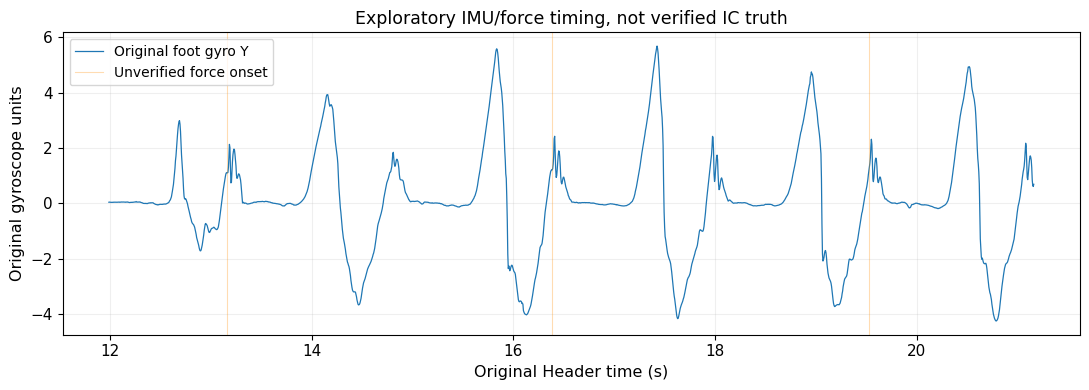

Source IMU overlay saved; it is NOT an event-accuracy result.


In [13]:
# ========================= 05. Inspect Aligned Trial =========================

if not reference_ready:
    print("Stage 05: plotting source IMU versus unverified force-contact "
          "candidates; formal alignment remains unverified.")
    if "provisional_events" in globals() and not provisional_events.empty:
        keys = ["subject_id", "session_id", "condition", "trial_id"]
        first = provisional_events.iloc[0]
        selection = pd.Series(True, index=pairs.index)
        for key in keys:
            selection &= pairs[key].astype(str).eq(str(first[key]))
        if int(selection.sum()) != 1:
            raise ValueError("Provisional contact maps to ambiguous IMU trial.")
        source_pair = pairs.loc[selection].iloc[0]
        imu = read_sensor_table(source_root / source_pair.imu_path)
        header = validate_timebase(imu, "IMU")
        if "foot_Gyro_Y" not in imu.columns:
            raise KeyError("Original foot_Gyro_Y channel not found.")
        trial_mask = pd.Series(True, index=provisional_events.index)
        for key in keys:
            trial_mask &= provisional_events[key].astype(str).eq(str(first[key]))
        onsets = provisional_events.loc[
            trial_mask, "candidate_onset_header"
        ].to_numpy(float)
        centre = float(onsets[0])
        visible = (header >= centre - 2) & (header <= centre + 8)
        fig, ax = plt.subplots(figsize=(11, 4))
        ax.plot(header[visible], imu.loc[visible, "foot_Gyro_Y"],
                lw=.9, label="Original foot gyro Y")
        n = 0
        for onset in onsets:
            if centre - 2 <= onset <= centre + 8:
                ax.axvline(
                    onset, linewidth=.8, alpha=.3, color="darkorange",
                    label="Unverified force onset" if n == 0 else None,
                )
                n += 1
        ax.set(
            xlabel="Original Header time (s)",
            ylabel="Original gyroscope units",
            title="Exploratory IMU/force timing, not verified IC truth",
        )
        ax.grid(alpha=.2)
        ax.legend()
        fig.tight_layout()
        save_figure(fig, output_dir / "02_provisional_imu_contact_overlay.png")
        plt.show()
        print("Source IMU overlay saved; it is NOT an event-accuracy result.")
else:

    # ------------------- 1. Stage Inputs and Main Analysis -------------------
    sample = eligible.iloc[0]
    t, g, ic = read_prepared_trial(cache_dir, sample.trial_key)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(t, g, label=f"IMU: {GYRO_COLUMN}", lw=1)
    for j, event in enumerate(ic):
        ax.axvline(event, color="darkorange", alpha=0.3,
                   label="Force-derived IC" if j == 0 else None)
    ax.set(xlabel="Reviewed original time (s)",
           ylabel="Gyroscope (source unit)", title="Eligible paired trial")
    ax.legend()

    # ---------------------- 2. Export Scientific Figure ----------------------
    fig.tight_layout()
    save_figure(fig, output_dir / "02_imu_reference_alignment.png")
    plt.show()
    print("Prepared numerical caches:", cache_dir)
    print("Output reference events:", output_dir / "02_reference_events.csv")


**06. Research Summary and Output Download**

The published [`02_source_contract_review.csv`](../../output/02_source_contract_review.csv) and [`02_source_contract_diagnostic.png`](../../output/02_source_contract_diagnostic.png) document original sensor inspection and **do not imply validated IC/TC events**. The `02_eligible_trials.csv`, `02_reference_events.csv`, `02_participant_roles.csv`, and alignment figure become scientific results **only after** the validated reference pathway is actually executed.

The final cell packages the newly generated and previously existing `02_` files from this runtime. It never downloads original sources or substitutes GitHub tables for missing MAT data. Candidate events are not verified `02_reference_events.csv`. It does not package raw Camargo archives or automatically commit files to GitHub.

**Published current output set:** The latest execution packaged 19 `02_` CSV/PNG files, including the [81-row auxiliary cross-check](../../output/02_auxiliary_source_crosscheck.csv), [contact quality review](../../output/02_candidate_quality_review.csv), [threshold-sensitivity figure](../../output/02_candidate_threshold_sensitivity.png), [original gait-phase audit](../../output/02_original_gcright_source_audit.csv) and [phase/force proximity comparison](../../output/02_original_phase_force_comparison.csv). The scientific reference, eligible-trial and participant-role outputs remain absent.

**Next targeted execution:** After restoring the same original MAT trial files if necessary, run Sections 00–02A.2 in order from the current `main` code. The new source-side comparison and filter-loss audit are cheap diagnostic additions; they do not generate `02_reference_events.csv` until the original physical contract is supported. Avoid rerunning Notebook 01 or downloading the participant archives merely to refresh Markdown or existing CSVs when the selected MAT files are still available.


In [14]:
# ================= 06. Research Summary and Output Download ==================

print("Verified force reference extracted:", bool(reference_ready))
print("Original MAT source inspected:", original_mat_ready)
print("Source candidate quality assessed:",
      bool("quality_review" in globals() and not quality_review.empty))
download_outputs_from_colab(
    folder="gait_analysis/output", stage=f"{NOTEBOOK_NUMBER:02d}",
)


Verified force reference extracted: False
Original MAT source inspected: True
Source candidate quality assessed: True
------------------------------------------------------------------------
Notebook 02
Files packaged: 26
  + 02_all_force_axes_source_probe.png
  + 02_auxiliary_source_crosscheck.csv
  + 02_candidate_contact_intervals.csv
  + 02_candidate_contact_trial_audit.csv
  + 02_candidate_force_probe.png
  + 02_candidate_quality_review.csv
  + 02_candidate_threshold_sensitivity.png
  + 02_contact_filter_loss_review.csv
  + 02_contract_evidence_by_trial.csv
  + 02_force_channel_screening.csv
  + 02_force_component_evidence.csv
  + 02_original_gcright_phase_resets.csv
  + 02_original_gcright_source_audit.csv
  + 02_original_phase_both_sides_comparison.csv
  + 02_original_phase_force_comparison.csv
  + 02_provisional_contact_candidates.csv
  + 02_provisional_contact_trial_summary.csv
  + 02_provisional_imu_contact_overlay.png
  + 02_provisional_participant_coverage.csv
  + 02_source_